<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab8_3_DecisionTrees_RF_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles de Decisión y Random Forests
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [Árboles](https://scikit-learn.org/stable/modules/tree.html) | [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest)

---

### Objetivos de aprendizaje

1. Explica cómo un árbol de decisión realiza predicciones dividiendo recursivamente las características.

2. Define la impureza de Gini y la ganancia de información, y describe cómo se eligen las divisiones.

3. Identifica el sobreajuste en árboles de decisión y aplica estrategias de poda.

4. Explica el bagging y cómo los bosques aleatorios mejoran los árboles individuales.

5. Entrena árboles de decisión y bosques aleatorios en `scikit-learn` para clasificación y regresión.

6. Aplica métodos basados en árboles para predecir la radiación de onda corta a partir de variables atmosféricas y de superficie.

7. Usa Random Forest para **regionalizar el caudal** de 136 cuencas peruanas (CAMELS-PE), evaluando el modelo con error OOB, importancia por permutación y validación cruzada por grupos.

## 1. Limitaciones de los Algoritmos Anteriores

Cada clasificador y regresor que hemos visto hasta ahora tiene una limitación notable:

| Algoritmo | Problema |
|---|---|
| Regresión lineal/logística | Solo puede trazar límites de decisión lineales (en línea recta); solo puede ajustar líneas rectas a los datos |
| SVM (lineal) | Misma limitación que los modelos lineales |
| SVM (RBF) | No lineal, pero muy lento con conjuntos de datos grandes ($O(N^2)$-$O(N^3)$); difícil de interpretar |
| Naive Bayes | Asume que las características son independientes entre sí |
| KNN | Lento en la predicción (debe calcular las distancias a todos los puntos de entrenamiento); falla en dimensiones altas |

Los **árboles de decisión** abordan muchos de estos problemas simultáneamente:

- Aprenden límites de decisión **no lineales** y superficies de regresión no lineales de forma natural.

- Son **rápidos** para entrenar y predecir.
- No requieren **escalado de características** (a diferencia de SVM, KNN y redes neuronales).

- Producen modelos **interpretables**: la lógica de decisión se puede representar mediante un diagrama de flujo comprensible para todos.

- Manejan **tanto clasificación como regresión** con el mismo marco.

- Manejan de forma natural **tipos de características mixtas** (continuas y categóricas).

Quizás lo más importante es que los árboles de decisión son la base de los **bosques aleatorios** y los **árboles potenciados por gradiente (XGBoost)**, que se encuentran consistentemente entre los métodos de aprendizaje automático de mayor rendimiento en ecología, teledetección y ciencias ambientales.

## 2. La intuición: El juego de las 20 preguntas con datos

### El juego

Probablemente hayas jugado a las "20 preguntas": una persona piensa en algo y las demás intentan adivinarlo haciendo preguntas de sí o no. La estrategia consiste en hacer preguntas que **eliminen tantas posibilidades como sea posible**:

- "¿Está vivo?" — divide el universo aproximadamente por la mitad.

- "¿Es más grande que una caja de pan?" — otra gran división.

- "¿Tiene pelo?" — reduce aún más las posibilidades.

Un buen jugador hace la pregunta más *informativa* en cada paso: la que divide las posibilidades restantes de la manera más equitativa.

### Un árbol de decisión hace exactamente esto

En cada paso, un árbol de decisión hace una única pregunta de sí o no sobre una característica que **separa mejor** los datos. Continúa haciendo preguntas —dividiendo los datos en cada paso— hasta llegar a una respuesta final.

### Ejemplo ecológico: Clasificación de un píxel satelital

Supongamos que queremos clasificar un píxel como **Bosque**, **Agua** o **Zona urbana** según sus valores espectrales:

```
¿Es NDVI > 0.4?
|
+-- Sí: ¿Es NIR > 3000?
|       |
|       +-- Sí --> BOSQUE
|       +-- No --> AGRICULTURA
|
+-- No: ¿Es Azul > 1000?
        |
        +-- Sí --> ZONA URBANA
        +-- No --> AGUA
```

Cada nodo interno formula una pregunta sobre **una característica** y **un umbral**. Cada nodo hoja proporciona una predicción. La ruta desde la raíz hasta la hoja constituye la regla de decisión completa, y es fácil de explicar a cualquiera.

### Ejemplo de regresión: Predicción de la radiación de onda corta

La misma estructura de árbol funciona para predecir un valor continuo:

```
¿Es SZA > 75 grados?
|
+-- Sí: ¿Es la fracción de nubes > 0.5?
|       |
|       +-- Sí --> SW = 50 W/m² (sol bajo + nublado)
|       +-- No --> SW = 120 W/m² (sol bajo pero cielo despejado)
|
+-- No: ¿Es AOD > 0.3?
        |
        +-- Sí --> SW = 400 W/m² (sol alto pero brumoso)
        +-- No --> SW = 600 W/m² (sol alto, cielo despejado)
```

En lugar de predecir una clase en cada hoja, el árbol predice el **valor objetivo promedio** de las muestras de entrenamiento que llegaron a esa hoja. Esto se denomina **árbol de regresión**.

## 3. ¿Cómo elige el árbol sus preguntas?

En cada nodo, el algoritmo del árbol considera **todas las divisiones posibles para cada característica** (todas las características y todos los valores umbral) y elige la que produce la **mayor mejora**. Pero, ¿cómo medimos la "mejora"?

### Para la clasificación: Impureza de Gini

La medida más común de pureza de un nodo es la **impureza de Gini**:

$$
G = 1 - \sum_{c=1}^{C} p_c^2
$$

donde $p_c$ es la proporción de la clase $c$ en un nodo y $C$ es el número total de clases.

**Cómo interpretar la impureza de Gini:**

- $G = 0$: el nodo es **perfectamente puro**; todas las muestras pertenecen a la misma clase. Este es el mejor resultado posible. Por ejemplo, si las 100 muestras de un nodo son "Bosque", entonces $G = 1 - 1^2 = 0$.

- $G = 0.5$ (para 2 clases): **impureza máxima** — las clases están mezcladas por igual. Por ejemplo, 50 Bosque y 50 Agua: $G = 1 - (0.5^2 + 0.5^2) = 0.5$. Este es el peor caso: el nodo no nos dice nada sobre la clase.

- Para $C$ clases, la impureza máxima es $G = 1 - 1/C$ (todas las clases están representadas por igual).

El objetivo del árbol es hacer que cada nodo hijo sea lo más puro posible; elige la división que produce la **mayor disminución en la impureza de Gini**. Esta disminución se denomina **ganancia de información**.

### Ejemplo resuelto

Supongamos que un nodo tiene 100 muestras: 60 Bosque, 40 Agua. El coeficiente de Gini antes de la división es:

$$
G_{\text{parent}} = 1 - (0.6^2 + 0.4^2) = 1 - (0.36 + 0.16) = 0.48
$$

Ahora consideremos una posible división: "NDVI > 0.4":
- **Hijo izquierdo** (NDVI > 0.4): 58 Bosque, 5 Agua (63 en total)

$G_L = 1 - (58/63)^2 - (5/63)^2 = 1 - 0.847 - 0.006 = 0.147$
- **Hijo derecho** (NDVI <= 0.4): 2 Bosque, 35 Agua (37 en total)

$G_R = 1 - (2/37)^2 - (35/37)^2 = 1 - 0.003 - 0.895 = 0.102$

Coeficiente de Gini ponderado tras la división:

$$
G_{\text{split}} = \frac{63}{100} \times 0.147 + \frac{37}{100} \times 0.102 = 0.093 + 0.038 = 0.131
$$

**Ganancia de información** = $G_{\text{parent}} - G_{\text{split}} = 0.48 - 0.131 = 0.349$

¡Una mejora considerable! Esta división separa eficazmente la mayoría de los píxeles de bosque (NDVI alto) de la mayoría de los píxeles de agua (NDVI bajo).

El árbol evalúa todas las posibles divisiones en cada característica y selecciona la que ofrece la **mayor ganancia de información**. Luego, repite el proceso para cada nodo hijo, de forma recursiva, hasta que se cumple algún criterio de parada.

### Para regresión: Reducción de varianza

En los árboles de regresión, el concepto es el mismo, pero la métrica cambia. En lugar de la impureza de Gini, el árbol minimiza la **varianza** (o, equivalentemente, el error cuadrático medio) dentro de cada nodo.

En cada división, el árbol selecciona el umbral que **minimiza la varianza ponderada total** de los valores objetivo en los dos nodos hijos. Intuitivamente, agrupa las muestras de entrenamiento que tienen valores objetivo similares.

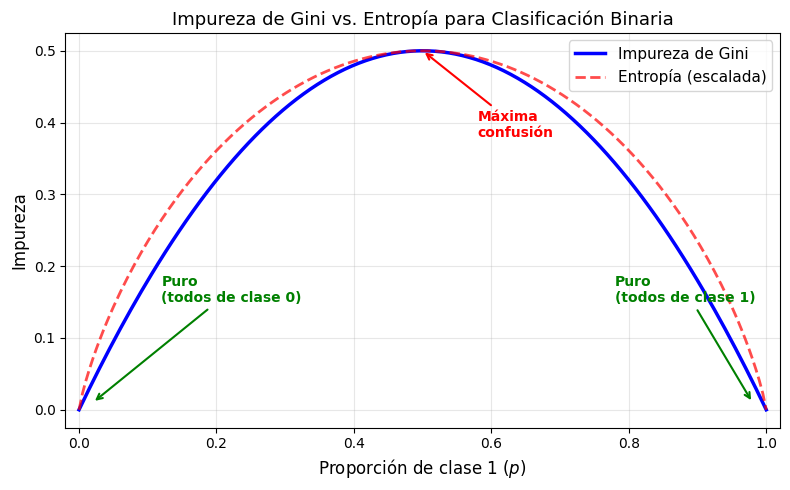

Ejemplos de impurezas de Gini:
    Toda la clase A (p=1.0): G = 0.00 (puro)
    90% A, 10% B (p=0.9):    G = 0.18
    70% A, 30% B (p=0.7):   G = 0.42
    50% A, 50% B (p=0.5):   G = 0.50 (impureza máxima)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
# ── Visualización de la impureza de Gini para clasificación binaria ──
p = np.linspace(0, 1, 200)
gini = 1 - p**2 - (1-p)**2
entropía = -p * np.log2(np.clip(p, 1e-10, 1)) - (1-p) * np.log2(np.clip(1-p, 1e-10, 1))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(p, gini, 'b-', linewidth=2.5, label='Impureza de Gini')
ax.plot(p, entropía / 2, 'r--', linewidth=2, label='Entropía (escalada)', alpha=0.7)

ax.set_xlabel('Proporción de clase 1 ($p$)', fontsize=12)
ax.set_ylabel('Impureza', fontsize=12)
ax.set_title('Impureza de Gini vs. Entropía para Clasificación Binaria', fontsize=13)

# Anotaciones
ax.annotate('Puro\n(todos de clase 0)', xy=(0.02, 0.01), fontsize=10,
            xytext=(0.12, 0.15), arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
            color='green', fontweight='bold')
ax.annotate('Puro\n(todos de clase 1)', xy=(0.98, 0.01), fontsize=10,
            xytext=(0.78, 0.15), arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
color='green', fontweight='bold')
ax.annotate('Máxima\nconfusión', xy=(0.5, 0.5), fontsize=10,
            xytext=(0.58, 0.38), arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
color='red', fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(-0.02, 1.02)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Ejemplos de impurezas de Gini:")
print(f"    Toda la clase A (p=1.0): G = {1 - 1**2 - 0**2:.2f} (puro)")
print(f"    90% A, 10% B (p=0.9):    G = {1 - 0.9**2 - 0.1**2:.2f}")
print(f"    70% A, 30% B (p=0.7):   G = {1 - 0.7**2 - 0.3**2:.2f}")
print(f"    50% A, 50% B (p=0.5):   G = {1 - 0.5**2 - 0.5**2:.2f} (impureza máxima)")

El gráfico muestra tanto la impureza de Gini como la entropía (otro criterio de división común, utilizado con `criterion='entropy'` en scikit-learn). Su forma es prácticamente idéntica: ambas son cero en los extremos (nodos puros) y alcanzan su máximo en 50/50. El cálculo de Gini es ligeramente más rápido, por lo que es el criterio predeterminado en scikit-learn.

La **entropía** utiliza la fórmula $H = -\sum p_c \log_2(p_c)$ y se basa en la teoría de la información. El criterio de división resultante se denomina **ganancia de información** (disminución de la entropía). En la práctica, Gini y la entropía generan árboles muy similares.

## 4. Árbol de Decisión en `scikit-learn`

Vamos a entrenar un árbol de decisión con el conjunto de datos Iris y a visualizar su estructura.

In [2]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics

# Datos de ejemplo: Iris (aplicable a clasificación de especies)
iris = load_iris()
X, y = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)

# Árbol sin restricción
arbol = DecisionTreeClassifier(random_state=42)
arbol.fit(X_tr, y_tr)

print(f"Exactitud entrenamiento: {arbol.score(X_tr, y_tr):.2%}")
print(f"Exactitud prueba:        {arbol.score(X_te, y_te):.2%}")
print(f"Profundidad del árbol:   {arbol.get_depth()}")
print(f"Número de hojas:         {arbol.get_n_leaves()}")

Exactitud entrenamiento: 100.00%
Exactitud prueba:        100.00%
Profundidad del árbol:   6
Número de hojas:         10


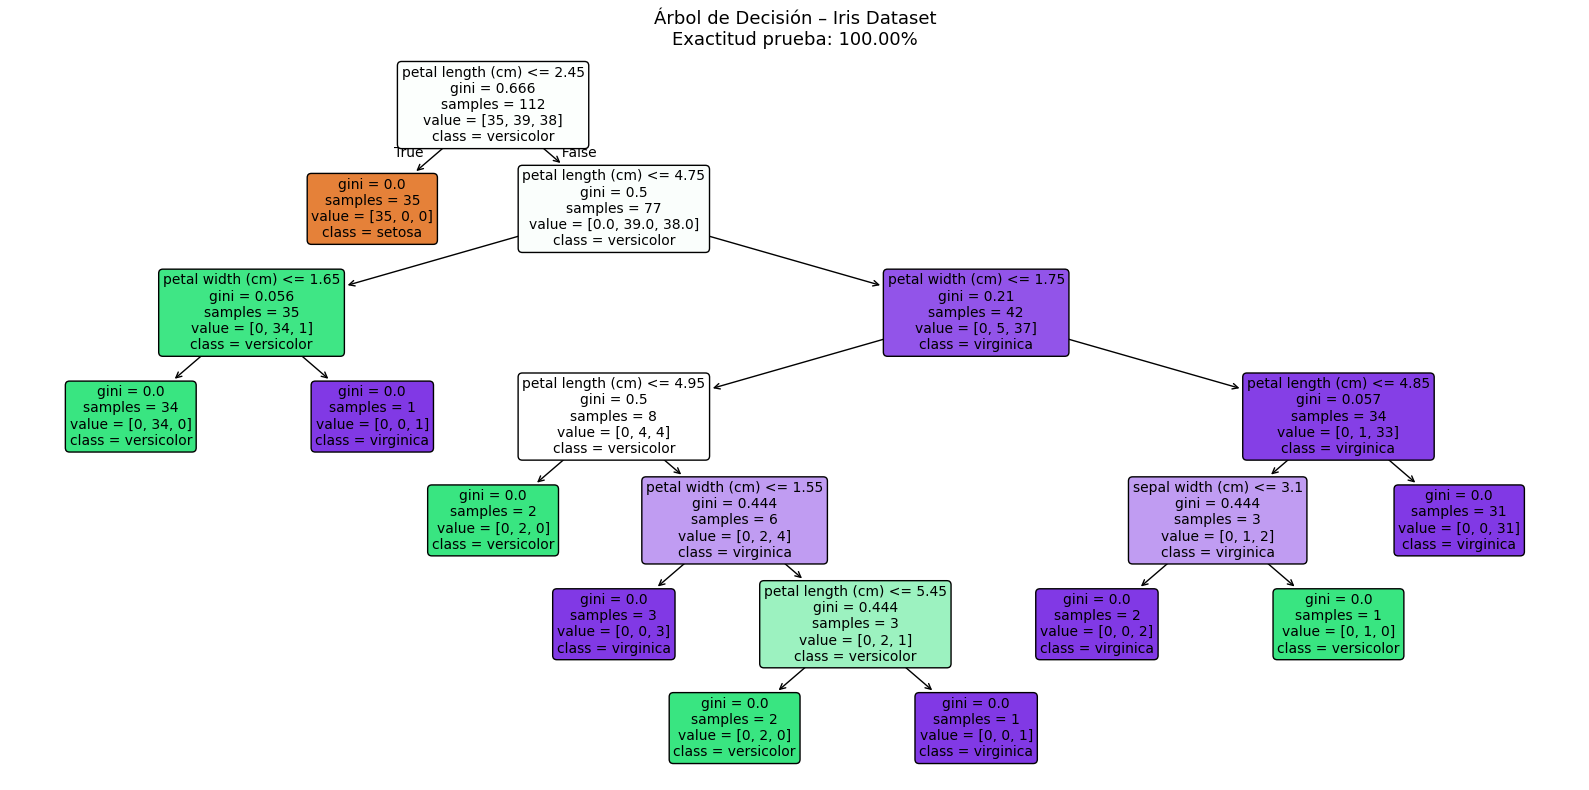

In [3]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(arbol, filled=True,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Árbol de Decisión – Iris Dataset\nExactitud prueba: {arbol.score(X_te, y_te):.2%}',
             fontsize=13)
plt.tight_layout()
plt.show()

### Interpretación de la visualización del árbol

Cada recuadro (nodo) del árbol muestra 5 datos:

1. **Condición de división** (p. ej., "ancho del pétalo (cm) <= 0.8"): pregunta de sí/no. Rama izquierda = Verdadero, Rama derecha = Falso.
2. **Impureza de Gini**: grado de mezcla de clases en este nodo. Un valor menor indica mayor pureza.
3. **Muestras**: número de ejemplos de entrenamiento que llegaron a este nodo.
4. **Valor**: distribución de clases; p. ej., [37, 0, 0] significa 37 setosa, 0 versicolor y 0 virginica.
5. **Clase**: clase mayoritaria (la predicción si este nodo fuera una hoja).

La **intensidad del color** refleja la pureza: un naranja/púrpura/verde más intenso indica que el nodo está dominado por una clase; el blanco indica un nodo mixto.

**Interpretación de una ruta de decisión:** Para clasificar una flor nueva, comience en el nodo raíz (superior) y siga las ramas de sí/no hacia abajo. Por ejemplo:
- "¿Ancho del pétalo <= 0.8?" → Sí → clasificar como **setosa** (¡se resuelve en una sola pregunta!)
- "¿Ancho del pétalo <= 0.8?" → No → "¿Ancho del pétalo <= 1.75?" → Sí → probablemente **versicolor**
- etc.

Observe que la primera división utiliza el **ancho del pétalo**, la característica más informativa para diferenciar las especies de Iris. El árbol lo descubrió automáticamente a partir de los datos.

Observe también que el árbol es bastante profundo y tiene muchas hojas. La precisión del entrenamiento es del 100%: el árbol memoriza perfectamente cada ejemplo de entrenamiento. Esto es un indicio de posible **sobreajuste**.

## 5. Sobreajuste y Poda

### El problema

Un árbol de decisión sin restricciones seguirá dividiendo hasta que cada hoja sea pura, clasificando perfectamente cada punto de entrenamiento. Esto suena bien, pero significa que el árbol ha **memorizado** los datos de entrenamiento, incluyendo todo su ruido, errores de medición e idiosincrasias.

Consideremos lo siguiente: si un píxel de entrenamiento tiene una firma espectral inusual debido a un fallo del sensor, un árbol sin podar creará una rama especial solo para ese píxel. Cuando encuentra un nuevo píxel, esa rama no aporta valor; es ruido, no señal.

El resultado: alta precisión en el entrenamiento, pero precisión significativamente menor en las pruebas. Esta diferencia es la característica principal del sobreajuste.

### La solución: controlar la complejidad del árbol

`scikit-learn` proporciona varios parámetros para limitar el crecimiento del árbol. Estas se denominan estrategias de **prepoda** porque evitan que el árbol crezca demasiado:

| Parámetro | Función | Valores típicos |
|---|---|---|
| `max_depth` | Limita la profundidad máxima (número de niveles) del árbol | 3–15 |
| `min_samples_split` | Un nodo debe tener al menos esta cantidad de muestras para poder dividirse aún más | 2–20 |
| `min_samples_leaf` | Cada nodo hoja debe tener al menos esta cantidad de muestras | 1–10 |
| `max_leaf_nodes` | Limita el número total de nodos hoja | 10–100 |

El parámetro más utilizado es `max_depth`. Veamos cómo afecta al rendimiento.

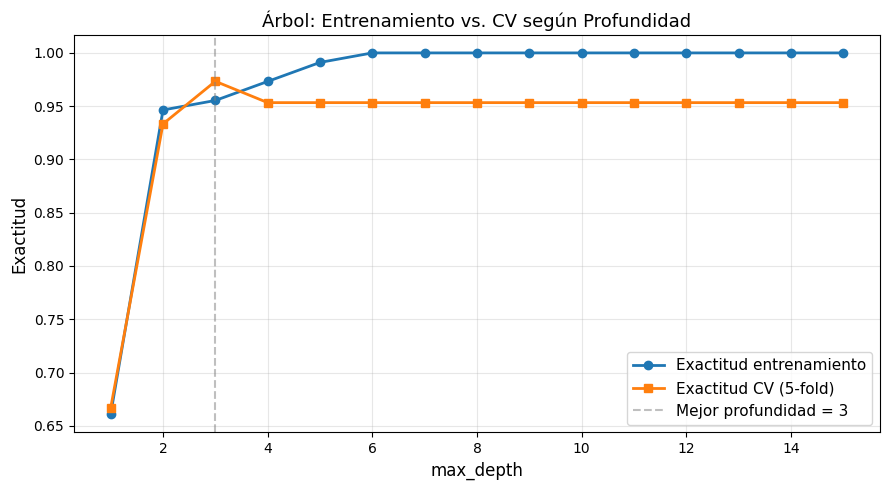

Mejor profundidad máxima por validación cruzada: 3
Precisión de validación cruzada a la mejor profundidad: 0.973
Precisión de entrenamiento a la mejor profundidad: 0.955

Patrones clave:
  - Profundidad 1-2: Subajuste (árbol demasiado simple)
  - Profundidad 3: Equilibrio óptimo
  - Profundidad 10+: Sobreajuste (memoriza ruido de entrenamiento)


In [4]:
# Barrer max_depth y comparar entrenamiento vs. CV
profundidades   = list(range(1, 16))
puntajes_train  = []
puntajes_cv     = []

for d in profundidades:
    arbol_d = DecisionTreeClassifier(max_depth=d, random_state=42)
    arbol_d.fit(X_tr, y_tr)
    puntajes_train.append(arbol_d.score(X_tr, y_tr))
    puntajes_cv.append(cross_val_score(arbol_d, X, y, cv=5).mean())

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(profundidades, puntajes_train, 'o-', linewidth=2, label='Exactitud entrenamiento')
ax.plot(profundidades, puntajes_cv, 's-', linewidth=2, label='Exactitud CV (5-fold)')

mejor_prof = profundidades[np.argmax(puntajes_cv)]
ax.axvline(mejor_prof, color='gray', linestyle='--', alpha=0.5, label=f'Mejor profundidad = {mejor_prof}')

ax.set_xlabel('max_depth', fontsize=12)
ax.set_ylabel('Exactitud', fontsize=12)
ax.set_title('Árbol: Entrenamiento vs. CV según Profundidad', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mejor profundidad máxima por validación cruzada: {mejor_prof}")
print(f"Precisión de validación cruzada a la mejor profundidad: {max(puntajes_cv):.3f}")
print(f"Precisión de entrenamiento a la mejor profundidad: {puntajes_train[mejor_prof-1]:.3f}")

print("\nPatrones clave:")
print("  - Profundidad 1-2: Subajuste (árbol demasiado simple)")
print(f"  - Profundidad {mejor_prof}: Equilibrio óptimo")
print("  - Profundidad 10+: Sobreajuste (memoriza ruido de entrenamiento)")

El patrón es claro:

- Con una profundidad baja (1-2), tanto la precisión del entrenamiento como la de la validación cruzada son bajas; el árbol es demasiado simple (subajuste).

- Con una profundidad moderada (3-5), la precisión de la validación cruzada alcanza su máximo; el árbol captura los patrones reales sin memorizar ruido.

- Con una profundidad alta (10+), la precisión del entrenamiento llega al 100%, pero la de la validación cruzada se estanca o disminuye; el árbol está memorizando ruido (sobreajuste).

La creciente diferencia entre la precisión del entrenamiento y la de la validación cruzada a profundidades altas es la señal clásica del sobreajuste.

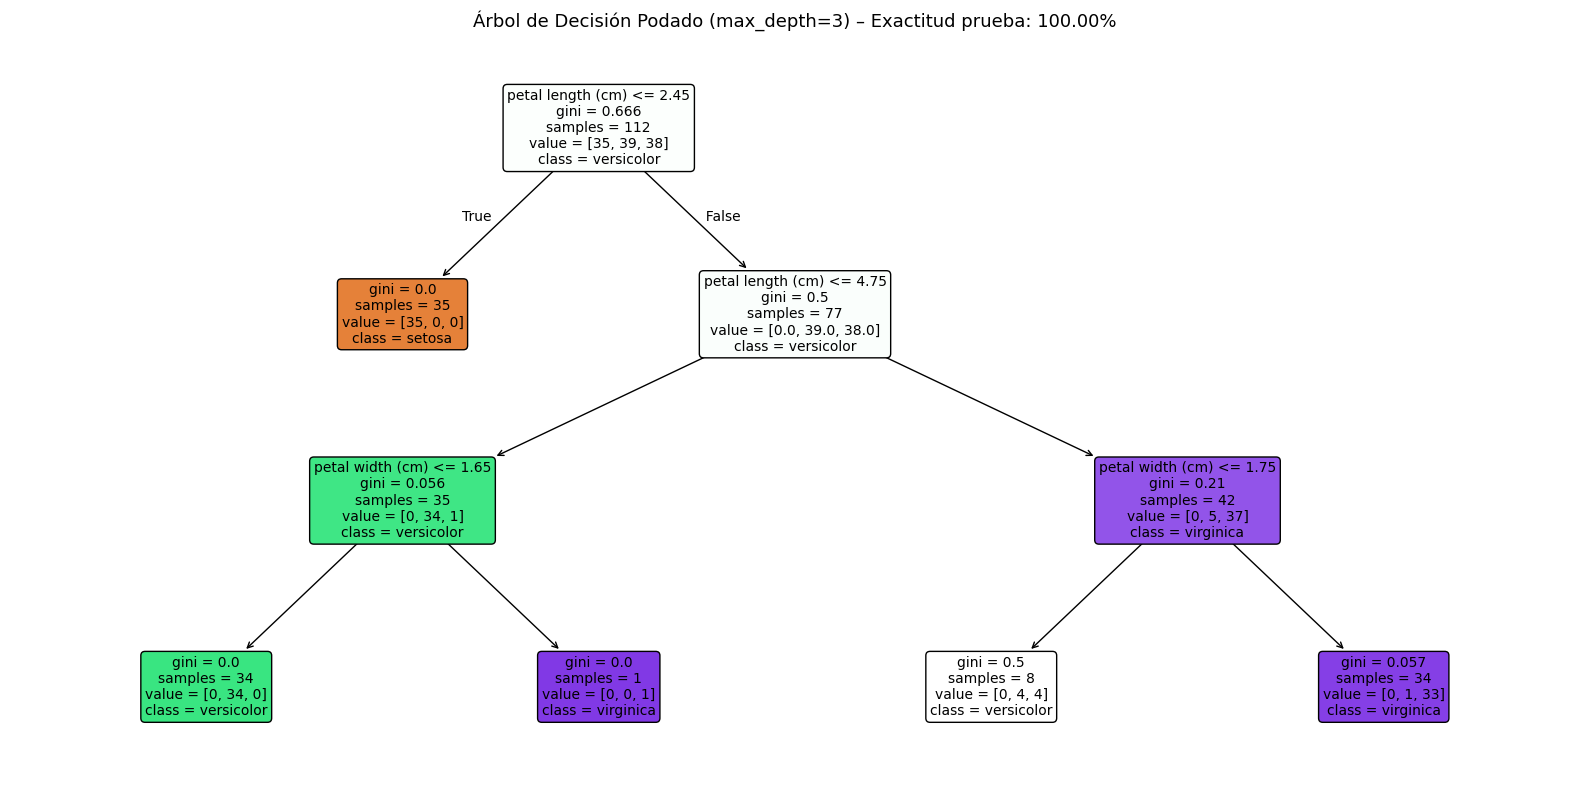

In [ ]:
# Visualizar árbol podado
arbol_podado = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_podado.fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(arbol_podado, filled=True,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Árbol de Decisión Podado (max_depth=3) – Exactitud prueba: {arbol_podado.score(X_te, y_te):.2%}',
             fontsize=13)
plt.tight_layout()
plt.show()

Este árbol podado tiene solo 3 niveles de profundidad —mucho más simple que el árbol completo— y, sin embargo, logra una precisión de prueba casi idéntica. Utiliza solo 2 o 3 características y es fácil de interpretar.

> **Principio clave:** Prefiera el modelo más simple que logre una precisión competitiva. Un árbol poco profundo, fácil de entender y que explica el 95 % de la varianza, suele ser mejor que un árbol profundo que memoriza el 100 % de los datos de entrenamiento pero que generaliza mal.

---
## 6. Visualizar las Fronteras de Decision

Los arboles de decision particionan el espacio en **regiones rectangulares** porque cada division es un umbral sobre una sola caracteristica (un corte vertical u horizontal). No pueden dibujar lineas diagonales o curvas directamente; en cambio, las aproximan con muchos pequeños escalones rectangulares.

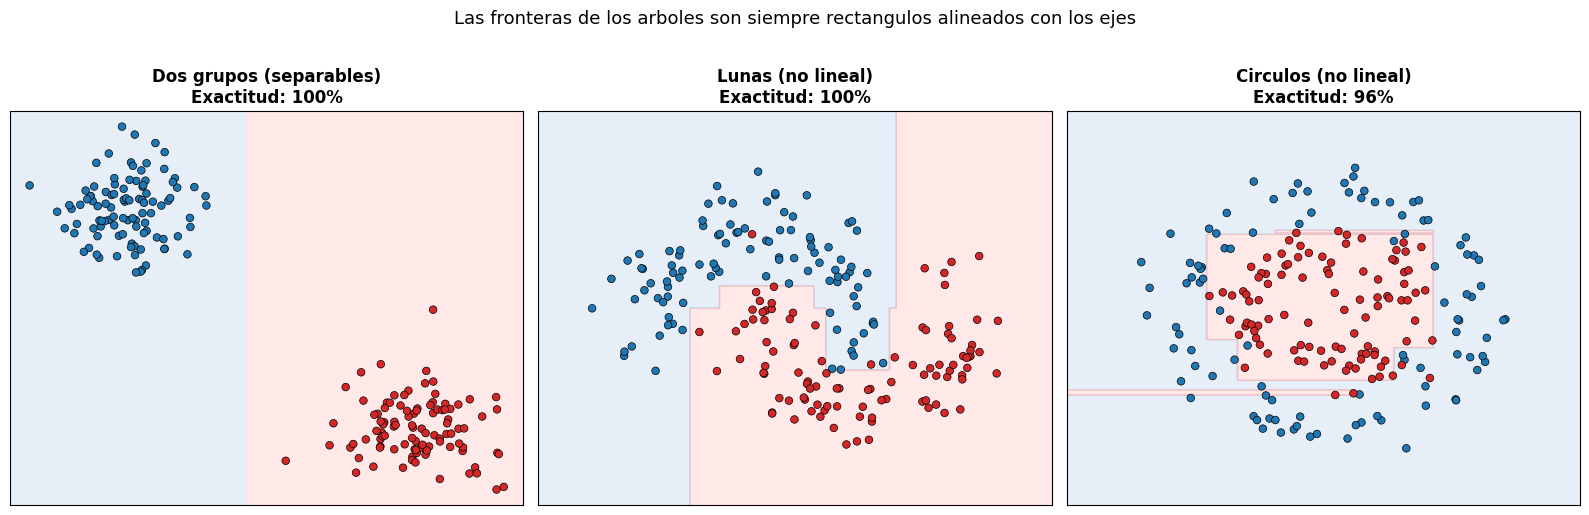

Notese el patron de escalones — los arboles aproximan curvas con muchos cortes rectangulares.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_moons, make_circles, make_blobs
from matplotlib.colors import ListedColormap
import numpy as np, matplotlib.pyplot as plt

datasets = [
    ("Dos grupos (separables)",  make_blobs(n_samples=200, centers=2, cluster_std=1.0, random_state=42)),
    ("Lunas (no lineal)",         make_moons(n_samples=200, noise=0.2, random_state=42)),
    ("Circulos (no lineal)",      make_circles(n_samples=200, factor=0.5, noise=0.15, random_state=42)),
]
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
cmap_f = ListedColormap(["#AEC7E8","#FFB3B3"])
cmap_p = ListedColormap(["#1f77b4","#d62728"])

for ax, (nombre, (X_ds, y_ds)) in zip(ejes, datasets):
    arbol_ds = DecisionTreeClassifier(max_depth=6, random_state=42).fit(X_ds, y_ds)
    x1,x2 = X_ds[:,0].min()-0.5, X_ds[:,0].max()+0.5
    y1,y2 = X_ds[:,1].min()-0.5, X_ds[:,1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x1,x2,300), np.linspace(y1,y2,300))
    Z = arbol_ds.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_f)
    ax.scatter(X_ds[:,0], X_ds[:,1], c=y_ds, cmap=cmap_p, edgecolors='k', s=30, linewidths=0.5)
    ax.set_title(f'{nombre}\nExactitud: {arbol_ds.score(X_ds,y_ds):.0%}', fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Las fronteras de los arboles son siempre rectangulos alineados con los ejes', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()
print("Notese el patron de escalones — los arboles aproximan curvas con muchos cortes rectangulares.")

Observe el patrón escalonado: cada límite es paralelo a uno de los ejes (cortes horizontales o verticales). Los árboles de decisión no pueden trazar líneas diagonales o curvas directamente. En cambio, aproximan las curvas con muchos pequeños pasos rectangulares.

Esto significa:
- Para **manchas** (separables linealmente): el árbol encuentra un límite nítido con muy pocas divisiones.

- Para **lunas** y **círculos**: el árbol aún puede clasificar correctamente, pero necesita muchas más divisiones, cada una de las cuales añade un pequeño corte rectangular para aproximar el límite curvo.

Compárese esto con SVM (curvas suaves) o KNN (límites irregulares). Los árboles sacrifican la suavidad de los límites a cambio de interpretabilidad y velocidad.

## 7. De un árbol a un bosque: Bosques aleatorios

### El problema de un solo árbol

Un solo árbol de decisión tiene una debilidad crítica: **alta varianza**. Pequeños cambios en los datos de entrenamiento —añadir o eliminar solo unas pocas muestras— pueden cambiar por completo la estructura del árbol. Una división aleatoria diferente de los datos de entrenamiento y prueba podría producir un árbol con características, umbrales y predicciones diferentes. Esta inestabilidad es un síntoma de sobreajuste.

### La sabiduría colectiva

He aquí una analogía. Si le pides a **una persona** que estime la cantidad de caramelos en un frasco, podría equivocarse enormemente: quizás demasiado, quizás demasiado poco. Pero si le preguntas a **100 personas** y tomas el **promedio** de sus estimaciones, sucede algo extraordinario: el promedio suele estar muy cerca del número real. Los errores individuales —algunos demasiado altos, otros demasiado bajos— se compensan.

Este fenómeno se llama **sabiduría colectiva** y es el principio fundamental de los **bosques aleatorios**.

### Cómo funcionan los bosques aleatorios

Un bosque aleatorio entrena **muchos árboles de decisión** (normalmente entre 100 y 500) y combina sus predicciones. La diversidad de los árboles se logra mediante dos formas de aleatoriedad:

**1. Muestreo Bootstrap (Bagging)**

Cada árbol se entrena con una **muestra bootstrap**, un subconjunto aleatorio de los datos de entrenamiento, extraído *con reemplazo*. "Con reemplazo" significa que algunos puntos de entrenamiento aparecen varias veces y otros se omiten por completo. Cada árbol ve una versión ligeramente diferente de los datos.

El nombre "bagging" significa **B**ootstrap **AGG**regat**ING**.

**2. Subconjuntos aleatorios de características**

En cada división de cada árbol, en lugar de considerar todas las características, el algoritmo selecciona aleatoriamente un **subconjunto de características** (normalmente $\sqrt{M}$ características para clasificación, $M/3$ para regresión, donde $M$ es el número total de características). La división se elige únicamente de este subconjunto.

Esto obliga a que los árboles sean **diversos**. Sin esto, si una característica (por ejemplo, el NDVI) es muy fuerte, todos los árboles se dividirían primero en función de ella, y todos los árboles se verían similares, lo que anularía el propósito del conjunto.

**3. Agregación**

Para la clasificación, cada árbol "vota" por una clase, y gana la **mayoría de votos**. Para la regresión, las predicciones se **promedian**.

### ¿Por qué funciona esto?

Cada árbol individual es un estimador ruidoso y potencialmente sobreajustado. Pero como los árboles se entrenan con diferentes subconjuntos de datos y utilizan diferentes subconjuntos de características, sus errores no están **correlacionados**. Cuando se promedian muchas estimaciones ruidosas no correlacionadas, el ruido se cancela y la señal permanece.

Matemáticamente: si cada árbol tiene varianza $\sigma^2$ y la correlación entre las predicciones de dos árboles es $\rho$, la varianza del promedio de $B$ árboles es

$$
\text{Var} = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2
$$

El segundo término desaparece al agregar más árboles, pero el primero **no**: por eso no basta con promediar muchos árboles, hay que hacerlos **poco correlacionados** (bootstrap + subconjuntos aleatorios de características reducen $\rho$). El sesgo, en cambio, se mantiene prácticamente igual al de un árbol individual.

Por eso los bosques aleatorios son tan robustos: rara vez sufren sobreajuste severo, incluso sin una optimización cuidadosa de los hiperparámetros.

## 8. Random Forests en `scikit-learn`

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics
import numpy as np

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# ── Entrenar Random Forest ──
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print(f"Precisión del Bosque Aleatorio: {metrics.accuracy_score(y_test, y_pred):.2%}")
print(f"Número de árboles: {rf.n_estimators}")

# ── Comparación con un solo árbol ──
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
print(f"Precisión de un solo árbol: {tree.score(X_test, y_test):.2%}")

# ── Comparación de validación cruzada ──
print(f"\nValidación cruzada de 5 pliegues:")
for name, clf in [("Árbol único", DecisionTreeClassifier(random_state=42)),
                  ("RF (100 árboles)", RandomForestClassifier(100, random_state=42)),
                  ("RF (500 árboles)", RandomForestClassifier(500, random_state=42))]:
    scores = cross_val_score(clf, X, y, cv=5)
    print(f" {name:20s}: {scores.mean():.3f} +/- {scores.std():.3f}")

Precisión del Bosque Aleatorio: 100.00%
Número de árboles: 100
Precisión de un solo árbol: 100.00%

Validación cruzada de 5 pliegues:
 Árbol único         : 0.953 +/- 0.034
 RF (100 árboles)    : 0.967 +/- 0.021
 RF (500 árboles)    : 0.967 +/- 0.021


El bosque aleatorio supera consistentemente al árbol de decisión único, y la mejora casi no conlleva complejidad adicional desde la perspectiva del usuario: el único parámetro nuevo es `n_estimators` (número de árboles).

> **¿Cuántos árboles?** La precisión generalmente mejora rápidamente de 1 a ~100 árboles, luego se estabiliza. Pasar de 100 a 500 árboles añade muy poca precisión pero duplica el tiempo de cálculo. Entre 100 y 200 árboles es un buen valor predeterminado para la mayoría de los conjuntos de datos.

### Prueba comparativa: Conjunto de datos Covertype

Compare los árboles de decisión, los bosques aleatorios y los demás clasificadores que hemos visto en un conjunto de datos más grande y realista: **Covertype** (tipo de cobertura forestal en Colorado, EE.UU., a partir de 54 variables cartográficas).

> La primera ejecución descarga el dataset (~11 MB) desde scikit-learn.

In [ ]:
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import time

covtype = fetch_covtype()
rng = np.random.RandomState(42)
idx = rng.choice(len(covtype.data), size=10000, replace=False)
X_sub, y_sub = covtype.data[idx], covtype.target[idx]

X_train, X_test, y_train, y_test = train_test_split(
X_sub, y_sub, test_size=0.25, random_state=42, stratify=y_sub
)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

classifiers = {
    "Árbol de decisión": (DecisionTreeClassifier(max_depth=15, random_state=42), X_train, X_test),
    "Bosque aleatorio": (RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train, X_test),
    "SVM (RBF)": (SVC(kernel="rbf"), X_train_sc, X_test_sc),
    "KNN (k=5)": (KNeighborsClassifier(n_neighbors=5), X_train_sc, X_test_sc),
    "Gaussian NB": (GaussianNB(), X_train_sc, X_test_sc),
}

print(f"Conjunto de datos: Covertype (N={len(X_sub)}, M={X_sub.shape[1]}, 7 clases)")
print(f"\n{'Clasificador':<20s} {'Entrenamiento (s)':>10s} {'Precisión':>10s} {'Escalado':>10s}")
print("-" * 55)

for name, (clf, Xtr, Xte) in classifiers.items():
    t0 = time.time()
    clf.fit(Xtr, y_train)
    t_train = time.time() - t0
    precisión = accuracy_score(y_test, clf.predict(Xte))
    escalado = "No" if name in ["Árbol de decisión", "Bosque aleatorio"] else "Sí"

    print(f"{name:<20s} {t_train:>10.3f} {precisión:>10.2%} {escalado:>10s}")

Conjunto de datos: Covertype (N=10000, M=54, 7 clases)

Clasificador         Entrenamiento (s)  Precisión   Escalado
-------------------------------------------------------
Árbol de decisión         0.163     73.00%         No
Bosque aleatorio          3.335     80.72%         No
SVM (RBF)                 2.796     74.08%         Sí
KNN (k=5)                 0.002     74.76%         Sí
Gaussian NB               0.008     14.12%         Sí


Los bosques aleatorios dominan esta comparación:

- **Máxima precisión**: el conjunto captura interacciones complejas y no lineales entre las 54 características.

- **No requiere escalado de características**: los árboles se dividen según umbrales de características individuales, no según distancias. Se pueden introducir los datos sin procesar directamente.

- **Entrenamiento rápido y paralelizable**: configure `n_jobs=-1` para usar todos los núcleos de la CPU.

- **Maneja altas dimensiones**: 54 características no suponen ningún problema; las características irrelevantes reciben automáticamente una importancia baja.

Por ello, los bosques aleatorios se han convertido en el método de referencia para la mayoría de las tareas de clasificación ecológica y de teledetección.

## 9. Importancia de las características

Uno de los resultados más valiosos de los modelos basados ​​en árboles es la **importancia de las características**, que clasifica las características que más contribuyen a las predicciones.

### Cómo funciona la importancia de Gini

Para cada característica, el algoritmo suma la **reducción total de la impureza de Gini** (para clasificación) o la **varianza** (para regresión) en todas las divisiones que utilizan esa característica, en todos los árboles del bosque. Las características elegidas con frecuencia para divisiones de alta calidad obtienen una alta importancia.

Las importancias se normalizan para que sumen 1,0.

Esto es increíblemente útil para la investigación ecológica, ya que indica qué variables ambientales son realmente relevantes para la predicción y cuáles se pueden eliminar sin perder rendimiento.

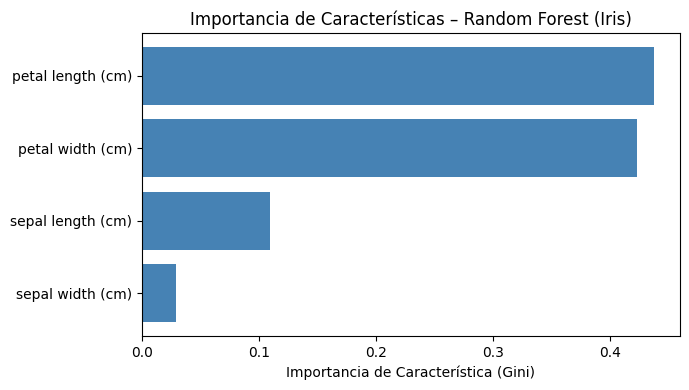

  petal length (cm)           : 0.438
  petal width (cm)            : 0.423
  sepal length (cm)           : 0.110
  sepal width (cm)            : 0.030


In [ ]:
# Importancia de características del Random Forest (Iris)
rf_iris = RandomForestClassifier(n_estimators=100, random_state=42)
rf_iris.fit(X_tr, y_tr)

importancias   = rf_iris.feature_importances_
idx_ordenado   = np.argsort(importancias)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(range(len(idx_ordenado)), importancias[idx_ordenado], color='steelblue')
ax.set_yticks(range(len(idx_ordenado)))
ax.set_yticklabels(np.array(iris.feature_names)[idx_ordenado])
ax.set_xlabel('Importancia de Característica (Gini)')
ax.set_title('Importancia de Características – Random Forest (Iris)')
plt.tight_layout()
plt.show()

for nombre, imp in sorted(zip(iris.feature_names, importancias), key=lambda x: -x[1]):
    print(f"  {nombre:<28}: {imp:.3f}")

El **ancho del pétalo** y el **largo del pétalo** son las características dominantes, lo cual coincide con las visualizaciones del árbol de decisión anteriores (la primera división siempre se basa en el ancho del pétalo).

Las características de los sépalos contribuyen mucho menos. Esto nos indica que, si solo tuvieras tiempo para medir dos aspectos de una flor de iris, medirías los pétalos.

Profundizaremos en la importancia de las características, incluyendo la importancia de la permutación y los valores SHAP, en el **Lab 8_4 (XGBoost y SHAP)**.

## 10. Aplicación: predecir la radiación solar desde variables atmosféricas

Esta es una aplicación importante para la meteorología y la energía solar en el Perú. Predecimos la **radiación solar de onda corta**
en superficie (SW, W/m²), separada en sus componentes **directa** y **difusa**, a partir de:

| Variable | Descripción | Unidad |
|----------|-------------|--------|
| `SZA` | Ángulo cenital solar | grados |
| `AOD` | Profundidad óptica de aerosoles | adimensional |
| `COD` | Profundidad óptica de nubes | adimensional |
| `CLD_FRAC` | Fracción de nubosidad | 0–1 |
| `UW` | Vapor de agua precipitable | cm |
| `TO3` | Ozono total en columna | DU |
| `Pressure` | Presión atmosférica en superficie | hPa |
| `BSA`, `WSA` | Albedo de cielo negro / cielo blanco | 0–1 |

> Los datos de esta sección son **sintéticos**, generados con relaciones físicas simplificadas (ley de Beer-Lambert para la radiación directa).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# ── Cargar el conjunto de datos ──
# Ajustar la ruta a la ubicación del archivo SW.csv
# Para Colab con Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/path/to/SW.csv')

# Para la demostración, generamos datos sintéticos que coinciden con la estructura esperada.
# Reemplazar este bloque con: df = pd.read_csv('SW.csv') cuando se utilicen datos reales.
np.random.seed(42)
n = 5000

SZA = np.random.uniform(0, 85, n)
AOD = np.random.exponential(0.15, n)
COD = np.random.exponential(5, n)
CLD_FRAC = np.random.uniform(0, 1, n)
UW = np.random.uniform(0.5, 5, n)
TO3 = np.random.uniform(250, 450, n)
Pressure = np.random.uniform(850, 1050, n)
BSA = np.random.uniform(0.05, 0.4, n)
WSA = np.random.uniform(0.05, 0.4, n)
# Objetivos sintéticos con base física
cos_sza = np.cos(np.radians(SZA))
SW_direct = np.maximum(0, 1361 * cos_sza * np.exp(-AOD / cos_sza) * (1 - CLD_FRAC * 0.9)
                       + np.random.normal(0, 15, n))
SW_diffuse = np.maximum(0, 200 * cos_sza * (0.3 + 0.5 * CLD_FRAC + 0.3 * AOD)
                        + np.random.normal(0, 10, n))

df = pd.DataFrame({
    'SZA': SZA, 'AOD': AOD, 'COD': COD, 'CLD_FRAC': CLD_FRAC,
    'UW': UW, 'TO3': TO3, 'Pressure': Pressure, 'BSA': BSA, 'WSA': WSA,
    'SW_direct': SW_direct, 'SW_diffuse': SW_diffuse
})
df['SW'] = df['SW_direct'] + df['SW_diffuse']

print(f"Forma del conjunto de datos: {df.shape}")
print(f"\nEstadísticas de características:")
print(df.describe().round(2))

Forma del conjunto de datos: (5000, 12)

Estadísticas de características:
           SZA      AOD      COD  CLD_FRAC       UW      TO3  Pressure  \
count  5000.00  5000.00  5000.00   5000.00  5000.00  5000.00   5000.00   
mean     42.23     0.14     5.06      0.51     2.79   348.26    950.12   
std      24.62     0.14     5.08      0.29     1.30    56.91     57.67   
min       0.00     0.00     0.00      0.00     0.50   250.02    850.00   
25%      20.73     0.04     1.42      0.26     1.67   299.43    899.50   
50%      42.50     0.10     3.43      0.51     2.81   348.20    950.38   
75%      63.59     0.20     7.15      0.75     3.91   396.43    999.65   
max      84.98     1.14    42.72      1.00     5.00   449.95   1049.96   

           BSA      WSA  SW_direct  SW_diffuse       SW  
count  5000.00  5000.00    5000.00     5000.00  5000.00  
mean      0.22     0.22     416.58       80.55   497.13  
std       0.10     0.10     307.09       41.15   314.92  
min       0.05     0.05    

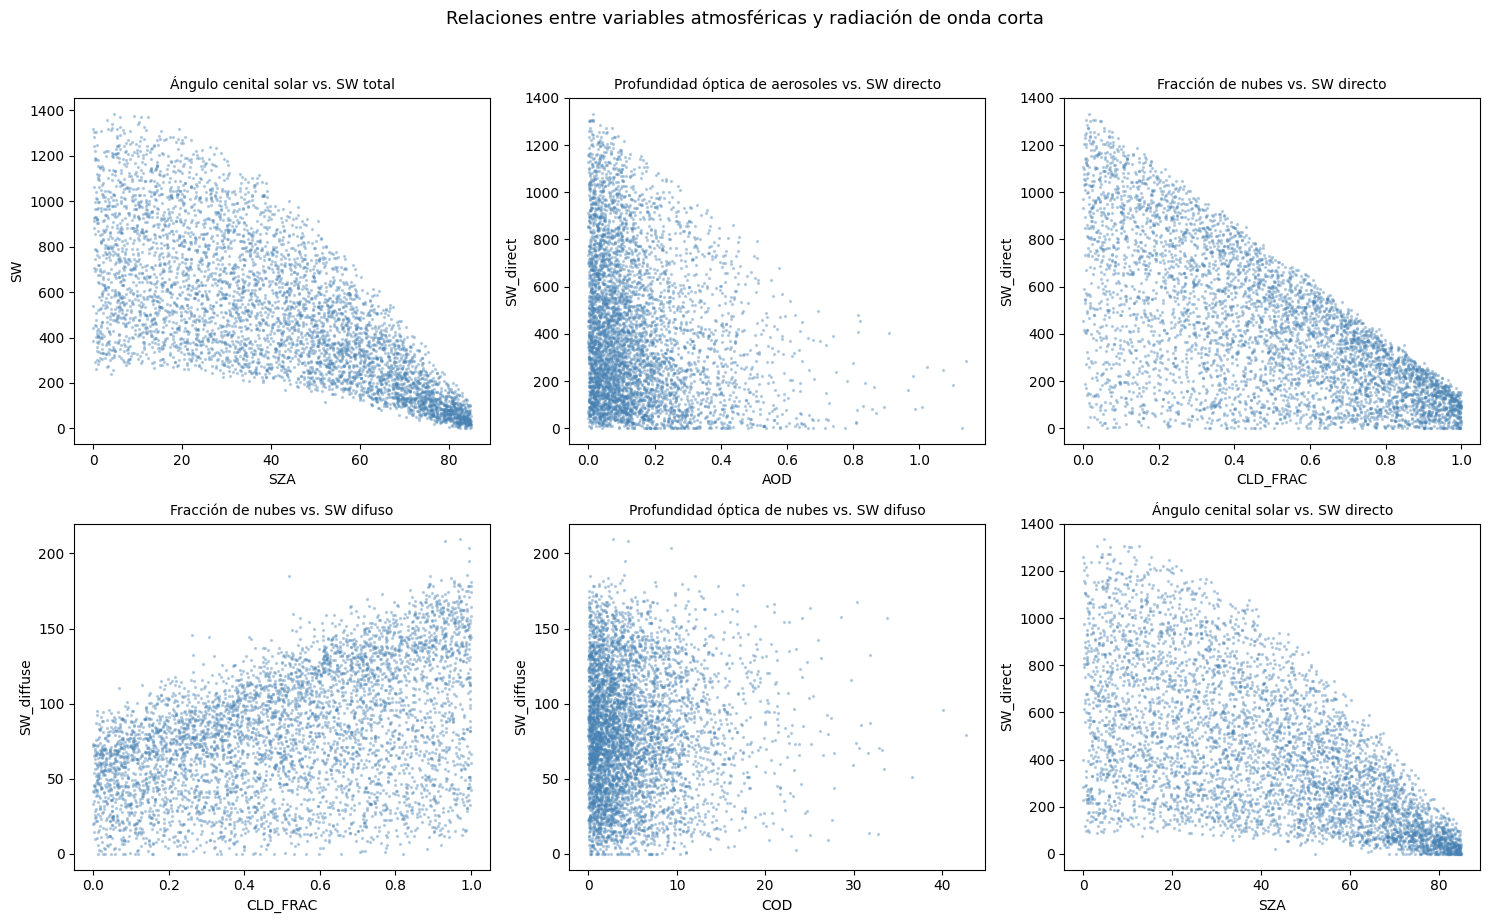

In [ ]:
# ── Explorar los datos: distribuciones y correlaciones ──
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Relaciones clave
pairs = [
    ('SZA', 'SW', 'Ángulo cenital solar vs. SW total'),
    ('AOD', 'SW_direct', 'Profundidad óptica de aerosoles vs. SW directo'),
    ('CLD_FRAC', 'SW_direct', 'Fracción de nubes vs. SW directo'),
    ('CLD_FRAC', 'SW_diffuse', 'Fracción de nubes vs. SW difuso'),
    ('COD', 'SW_diffuse', 'Profundidad óptica de nubes vs. SW difuso'),
    ('SZA', 'SW_direct', 'Ángulo cenital solar vs. SW directo'),
]

for ax, (xvar, yvar, title) in zip(axes.flat, pairs):
    ax.scatter(df[xvar], df[yvar], s=2, alpha=0.3, color='steelblue')
    ax.set_xlabel(xvar, fontsize=10)
    ax.set_ylabel(yvar, fontsize=10)
    ax.set_title(title, fontsize=10)

plt.suptitle('Relaciones entre variables atmosféricas y radiación de onda corta',
            fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Estos diagramas de dispersión revelan la física subyacente:

- **SZA vs. SW:** Fuerte relación no lineal. A medida que el sol desciende (mayor SZA), la radiación SW total disminuye drásticamente. La relación sigue una curva cosenoidal.

- **AOD vs. SW_directa:** Una mayor cantidad de aerosoles atenúa la radiación directa. La relación es exponencial (ley de Beer-Lambert).

- **CLD_FRAC vs. SW_directa:** Una mayor cantidad de nubes bloquea la luz solar directa; fuerte relación negativa.

- **CLD_FRAC vs. SW_difusa:** Una mayor cantidad de nubes *aumenta* la radiación difusa (hasta cierto punto) porque dispersa la luz solar en todas direcciones.

- **COD vs. SW_difusa:** Las nubes más densas dispersan más, aumentando inicialmente la radiación difusa y luego bloqueándola por completo cuando son extremadamente densas.

Todas estas son relaciones **no lineales**, precisamente donde los métodos basados ​​en árboles deberían superar a la regresión lineal.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import time

# ── Preparar características y objetivos ──
feature_cols = ['SZA', 'AOD', 'COD', 'CLD_FRAC', 'UW', 'TO3', 'Pressure', 'BSA', 'WSA']
target_cols = ['SW_direct', 'SW_diffuse', 'SW']
X = df[feature_cols].values
y_direct = df['SW_direct'].values
y_diffuse = df['SW_diffuse'].values
y_total = df['SW'].values

X_train, X_test, yd_train, yd_test, yf_train, yf_test, yt_train, yt_test = (
    train_test_split(X, y_direct, y_diffuse, y_total,
                     test_size=0.25, random_state=42)
)
# ── Entrenar modelos para SW total ──
models = {
    'Regresión lineal': LinearRegression(),
    'Árbol de decisión (profundidad=10)': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Árbol de decisión (ilimitado)': DecisionTreeRegressor(random_state=42),
    'Bosque aleatorio (100 árboles)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

print("=== Predicción de la radiación total de onda corta (SW = SW_directa + SW_difusa) ===")
print(f"{'Modelo':<30s} {'R2 de entrenamiento':>10s} {'R2 de prueba':>10s} {'RMSE de prueba':>10s} {'Tiempo (s)':>10s}")
print("-" * 75)

fitted_models = {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, yt_train)
    tt = time.time() - t0

    r2_entrenamiento = r2_score(yt_train, model.predict(X_train))
    r2_test = r2_score(yt_test, model.predict(X_test))
    rmse_test = np.sqrt(mean_squared_error(yt_test, model.predict(X_test)))

    fitted_models[name] = model
    print(f"{name:<30s} {r2_entrenamiento:>10.4f} {r2_test:>10.4f} {rmse_test:>10.1f} {tt:>10.3f}")

=== Predicción de la radiación total de onda corta (SW = SW_directa + SW_difusa) ===
Modelo                         R2 de entrenamiento R2 de prueba RMSE de prueba Tiempo (s)
---------------------------------------------------------------------------
Regresión lineal                   0.8913     0.8790      108.5      0.027
Árbol de decisión (profundidad=10)     0.9968     0.9809       43.1      0.066
Árbol de decisión (ilimitado)      1.0000     0.9799       44.2      0.075
Bosque aleatorio (100 árboles)     0.9989     0.9926       26.9      3.259


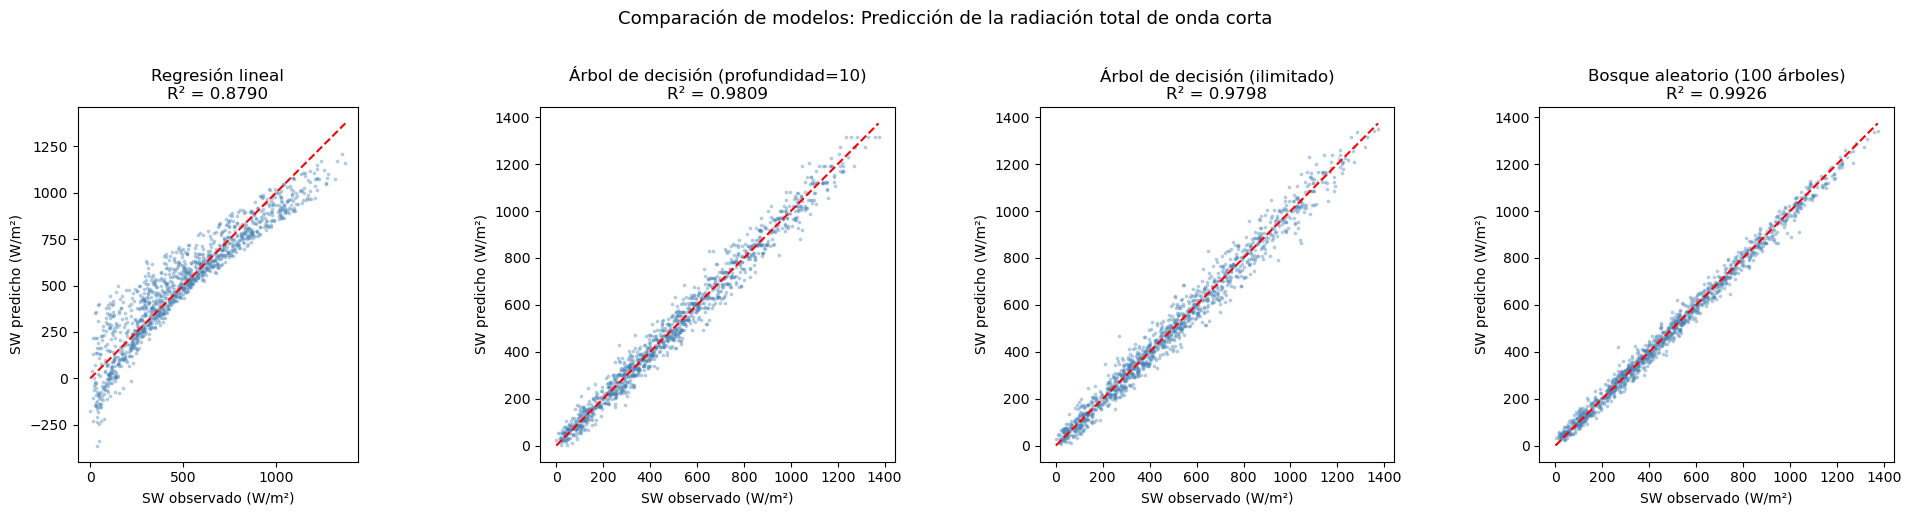

In [ ]:
# ── Gráficos 1:1 para cada modelo ──
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (name, model) in zip(axes, fitted_models.items()):
    y_pred = model.predict(X_test)
    r2 = r2_score(yt_test, y_pred)

    ax.scatter(yt_test, y_pred, s=3, alpha=0.3, color='steelblue')
    ax.plot([0, yt_test.max()], [0, yt_test.max()], 'r--', linewidth=1.5)
    ax.set_xlabel('SW observado (W/m²)')
    ax.set_ylabel('SW predicho (W/m²)')
    ax.set_title(f'{name}\nR² = {r2:.4f}')
    ax.set_aspect('equal')

plt.suptitle('Comparación de modelos: Predicción de la radiación total de onda corta',
            fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Observaciones clave

- La **regresión lineal** captura el efecto dominante del ángulo cenital solar (SZA), pero no puede modelar las interacciones no lineales entre aerosoles y nubes. Su gráfico 1:1 muestra una dispersión sistemática.

- El **árbol de decisión (ilimitado)** presenta sobreajuste: un R² de entrenamiento casi perfecto, pero un R² de prueba notablemente menor.

- El **árbol de decisión (profundidad=10)** sacrifica algo de ajuste de entrenamiento a cambio de una mejor generalización.

- El **bosque aleatorio** logra el mejor R² de prueba: el conjunto suaviza el ruido de los árboles individuales.

La ventaja del bosque aleatorio es especialmente visible en el gráfico 1:1: los puntos se agrupan estrechamente alrededor de la diagonal con una dispersión mínima.

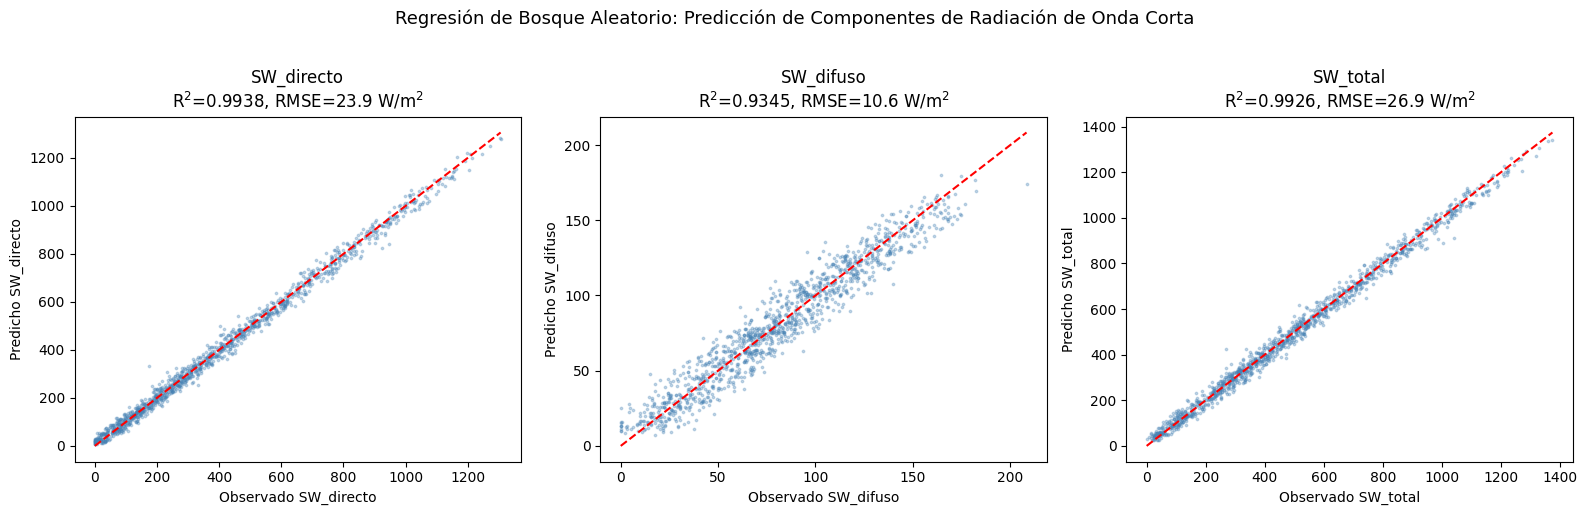

In [ ]:
# ── Predicción de los tres objetivos con Bosque Aleatorio ──
objetivos = {'SW_directo': (yd_train, yd_test),
             'SW_difuso': (yf_train, yf_test),
             'SW_total': (yt_train, yt_test)}

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (target_name, (y_tr, y_te)) in zip(ejes, objetivos.items()):
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_tr)

    y_pred = rf_model.predict(X_test)
    r2 = r2_score(y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))

    ax.scatter(y_te, y_pred, s=3, alpha=0.3, color='steelblue')
    max_val = max(y_te.max(), y_pred.max())
    ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5)
    ax.set_xlabel(f'Observado {target_name}')
    ax.set_ylabel(f'Predicho {target_name}')
    ax.set_title(f'{target_name}\nR$^2$={r2:.4f}, RMSE={rmse:.1f} W/m$^2$')

plt.suptitle('Regresión de Bosque Aleatorio: Predicción de Componentes de Radiación de Onda Corta',
            fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

El algoritmo de bosques aleatorios produce predicciones excelentes para los tres objetivos. **SW_direct** es más fácil de predecir (dominado por la relación coseno del ángulo cenital solar), mientras que **SW_diffuse** es más difícil (dependencia más compleja de las propiedades de las nubes y los aerosoles).

### Importancia de la característica: ¿Qué impulsa la radiación de onda corta?

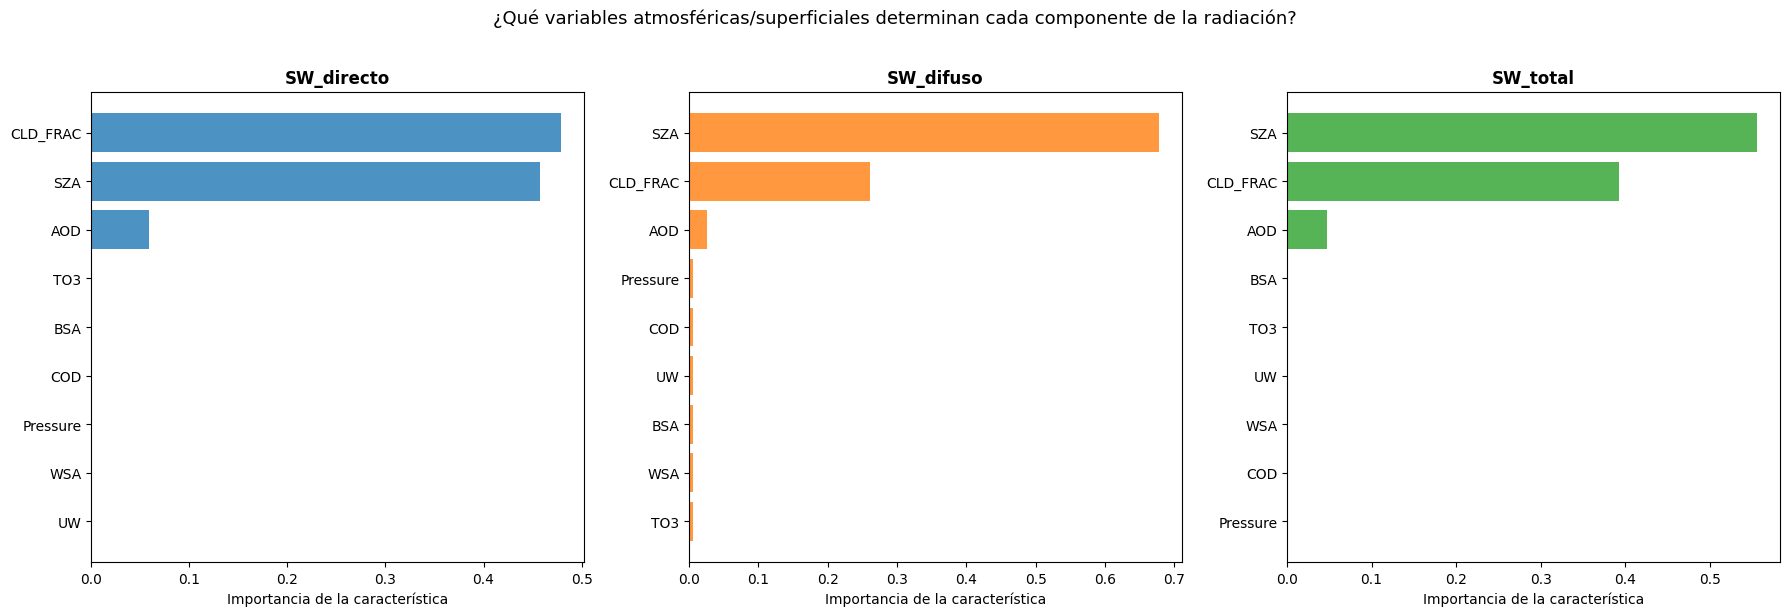

In [ ]:
# ── Importancia de las características para cada objetivo ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors_list = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, (target_name, (y_tr, y_te)), color in zip(axes, objetivos.items(), colors_list):
    rf_fi = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_fi.fit(X_train, y_tr)

    imp = rf_fi.feature_importances_
    sorted_idx = np.argsort(imp)

    ax.barh(range(len(sorted_idx)), imp[sorted_idx], color=color, alpha=0.8)
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels(np.array(feature_cols)[sorted_idx])
    ax.set_xlabel('Importancia de la característica')
    ax.set_title(f'{target_name}', fontweight='bold')

plt.suptitle('¿Qué variables atmosféricas/superficiales determinan cada componente de la radiación?',
            fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Interpretación ecológica/física

Los gráficos de importancia de las características revelan información físicamente significativa:

**Radiación directa en superficie (SW_direct):**
- **El ángulo cenital solar (SZA)** es el factor dominante: el ángulo solar controla principalmente la cantidad de radiación directa que llega a la superficie (ley del coseno).

- **CLD_FRAC** ocupa el segundo lugar: las nubes bloquean la luz solar directa.

- **AOD** ocupa el tercer lugar: los aerosoles atenúan la radiación directa (ley de Beer-Lambert).

**Radiación difusa en superficie (SW_diffuse):**
- **SZA** sigue siendo relevante (controla la radiación total disponible).

- **CLD_FRAC** y **COD** son importantes: las nubes dispersan la luz solar, convirtiendo la radiación directa en radiación difusa.

- **AOD** contribuye: los aerosoles también dispersan la radiación.

**Radiación total en superficie (SW_total: suma de radiación directa + difusa):**
- **SZA** es el factor dominante en general.

- Tanto las variables de nubes como las de aerosoles contribuyen, ya que redistribuyen la radiación entre los componentes directos y difusos.

Estos resultados son **físicamente consistentes** con la teoría de la transferencia radiativa, y el bosque aleatorio aprendió estas relaciones completamente a partir de los datos, sin necesidad de conocer ningún principio físico.

> **Este es un caso de uso poderoso para el aprendizaje automático en ciencias ambientales:** la creación de emuladores rápidos que aproximan modelos complejos basados ​​en la física. Un bosque aleatorio entrenado con la salida de un modelo de transferencia radiativa puede producir estimaciones de SW miles de veces más rápido que ejecutar el modelo completo, lo que permite aplicaciones en tiempo real e integración en modelos del sistema terrestre.

---
## 11. Aplicación real: regionalización del caudal con CAMELS-PE

En el Perú la mayoría de los ríos **no tienen estación hidrométrica**. Una pregunta central de la hidrología es:
*¿podemos estimar el comportamiento del caudal de una cuenca no aforada a partir de sus características físicas?*
Esto se llama **regionalización**, y Random Forest es una de las herramientas más usadas para hacerlo.

En el Lab 8_2 vimos con PCA que unos pocos gradientes (humedad, altitud) resumen los atributos de las cuencas
CAMELS-PE y se relacionan con el caudal. Ahora vamos un paso más allá: **predecir** firmas hidrológicas con Random Forest.

**Objetivo:** `q_mean`, el caudal medio específico (mm/día, es decir, caudal normalizado por el área de la cuenca).

**Predictores:** atributos de clima, topografía, cobertura, suelo, geología, intervención humana y ubicación.

> ⚠️ **Fuga de información (*data leakage*):** las demás firmas hidrológicas (`runoff_ratio`, `Q95`, `baseflow_index`, …)
> se calculan **a partir del mismo caudal observado**. Usarlas como predictores sería hacer trampa: en una cuenca
> sin estación no las conoceríamos. Solo usamos atributos que se pueden calcular sin medir el caudal.

### El dataset CAMELS-PE

**CAMELS-PE** (*Catchment Attributes and Meteorology for Large-sample Studies – Perú*, SENAMHI, v1.0) reúne
**136 cuencas** con estaciones hidrométricas del SENAMHI, distribuidas en las tres vertientes del país:

| Vertiente | Cuencas |
|---|---|
| Pacífico | 67 |
| Atlántico (Amazonas) | 56 |
| Titicaca | 13 |

Para cada cuenca hay **atributos estáticos** (una fila por cuenca) derivados de productos nacionales e internacionales:

| Grupo | Ejemplos | Fuente |
|---|---|---|
| Clima | `p_mean`, `pet_mean`, `aridity`, `p_seasonality` | PISCOp, PISCOeo_pm |
| Topografía | `area`, `elev_mean`, `slope_mean` | FABDEM |
| Cobertura | `forest_perc`, `agricul_perc`, `non_woody_perc` | MapBiomas |
| Suelos | `inceptisols_perc`, `ultisols_perc`, `entisols_perc` | DSOLMap |
| Geología | `geol_porosity`, `geol_permeability` | GLiM / GLHYMPS |
| Intervención humana | `reservoir_n`, `surface_adh_n` | ANA |
| Firmas hidrológicas | `q_mean`, `runoff_ratio`, `baseflow_index` | SENAMHI / PISCO_ARNOVIC |

Unidades: precipitación, ETP y caudal en **mm/día**; área en km²; elevación en msnm; coberturas y suelos en %.

> El archivo `camels_pe_atributos.csv` une `stations.csv` y los 7 archivos de `02_attributes/` por `gauge_id`.
> El diccionario completo de variables está en `camels_pe_diccionario.csv`.

In [ ]:
# ── Cargar atributos de CAMELS-PE (1 fila = 1 cuenca) ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os

# Montar Google Drive en Colab
from google.colab import drive
drive.mount('/content/drive')

# OPCION A: leer el archivo desde la carpeta compartida del curso en tu Drive
fname = '/content/drive/MyDrive/.../CDA_share/1_datasets/CAMELS-PE/camels_pe_atributos.csv'

# OPCION B: si esa carpeta no está en tu Drive, descargar el archivo compartido con gdown
if not os.path.exists(fname):
    import gdown
    ID = "1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ"
    fname = gdown.download(f"https://drive.google.com/uc?id={ID}", "camels_pe_atributos.csv", quiet=False)

camels = pd.read_csv(fname)
print(f"CAMELS-PE: {camels.shape[0]} cuencas x {camels.shape[1]} columnas")
print(camels["gauge_region"].value_counts().to_string())

# Colores por vertiente (paleta apta para daltonismo)
colores_vertiente = {"Pacific": "#E69F00", "Atlantic": "#009E73", "Titicaca": "#0072B2"}
nombres_vertiente = {"Pacific": "Pacífico", "Atlantic": "Atlántico", "Titicaca": "Titicaca"}

camels[["gauge_id", "gauge_name", "gauge_region", "gauge_lat", "gauge_lon",
        "p_mean", "aridity", "elev_mean", "forest_perc", "q_mean"]].head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Downloading...
From: https://drive.google.com/uc?id=1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ
To: /content/camels_pe_atributos.csv
100%|██████████| 71.2k/71.2k [00:00<00:00, 37.2MB/s]


CAMELS-PE: 136 cuencas x 79 columnas
gauge_region
Pacific     67
Atlantic    56
Titicaca    13


,gauge_id,gauge_name,gauge_region,gauge_lat,gauge_lon,p_mean,aridity,elev_mean,forest_perc,q_mean
0,PE_472A9204,Chilca,Atlantic,-13.223,-72.343,2.297,1.465,4210.225,1.389,0.933
1,PE_210003,Huancasaya,Titicaca,-15.142,-69.213,1.842,1.578,4659.078,0.050,0.488
2,PE_204617,Huatiapa,Pacific,-16.009,-72.483,1.503,2.423,4213.036,1.373,0.406
3,PE_472935F2,Intihuatana Km105,Atlantic,-13.185,-72.524,2.302,1.455,4196.945,1.876,1.081
4,PE_210406,Puente Isla Cabanillas,Titicaca,-15.473,-70.222,2.058,1.627,4467.149,0.000,0.699


In [ ]:
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

predictores = {
    'Clima':      ['p_mean', 'pet_mean', 'aridity', 'p_seasonality', 'high_prec_freq',
                   'high_prec_dur', 'low_prec_freq', 'low_prec_dur'],
    'Topografía': ['area', 'elev_min', 'elev_max', 'elev_mean', 'slope_mean'],
    'Cobertura':  ['forest_perc', 'agricul_perc', 'non_woody_perc', 'non_veget_perc', 'water_perc'],
    'Suelo':      ['inceptisols_perc', 'ultisols_perc', 'entisols_perc', 'alfisols_perc'],
    'Geología':   ['geol_porosity', 'geol_permeability', 'inter_volca_rocks_perc'],
    'Humano':     ['surface_adh_n', 'groundwater_adh_n', 'reservoir_n'],
    'Ubicación':  ['gauge_lat', 'gauge_lon'],
}
cols_rf = sum(predictores.values(), [])
objetivo = 'q_mean'

X_cam = camels[cols_rf]
y_cam = camels[objetivo]
print(f"X: {X_cam.shape[0]} cuencas x {X_cam.shape[1]} predictores; valores faltantes: {X_cam.isna().sum().sum()}")
print(f"y = {objetivo}: min {y_cam.min():.2f}, mediana {y_cam.median():.2f}, max {y_cam.max():.2f} mm/día")

X: 136 cuencas x 30 predictores; valores faltantes: 0
y = q_mean: min 0.03, mediana 0.96, max 7.87 mm/día


### 11.1 Comparar modelos con validación cruzada

Con solo 136 cuencas no conviene "gastar" un 25% en un único conjunto de prueba: el resultado dependería mucho de qué cuencas
cayeron ahí. Usamos **validación cruzada de 5 pliegues** (*5-fold CV*) y reportamos el promedio.

Observa que **no escalamos** las variables para los árboles; solo la regresión lineal las necesita.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

modelos_cam = {
    'Regresión lineal':      make_pipeline(StandardScaler(), LinearRegression()),
    'Árbol (max_depth=4)':   DecisionTreeRegressor(max_depth=4, random_state=42),
    'Árbol (ilimitado)':     DecisionTreeRegressor(random_state=42),
    'Random Forest (500)':   RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                                   random_state=42, n_jobs=-1),
}

filas = []
for nombre, modelo in modelos_cam.items():
    r = cross_validate(modelo, X_cam, y_cam, cv=cv, return_train_score=True,
                       scoring=('r2', 'neg_root_mean_squared_error'))
    filas.append({'Modelo': nombre,
                  'R² entrenamiento': r['train_r2'].mean(),
                  'R² CV': r['test_r2'].mean(),
                  'R² CV (desv. est.)': r['test_r2'].std(),
                  'RMSE CV (mm/día)': -r['test_neg_root_mean_squared_error'].mean()})
tabla_cam = pd.DataFrame(filas).set_index('Modelo').round(3)
tabla_cam

,R² entrenamiento,R² CV,R² CV (desv. est.),RMSE CV (mm/día)
Modelo,,,,
Regresión lineal,0.930,0.706,0.166,0.678
Árbol (max_depth=4),0.972,0.535,0.371,0.795
Árbol (ilimitado),1.000,0.616,0.363,0.721
Random Forest (500),0.967,0.732,0.275,0.566


**Lectura de la tabla:**

- El **árbol ilimitado** memoriza (R² de entrenamiento = 1) y generaliza peor: sobreajuste clásico.
- La **regresión lineal** es un rival serio aquí. `q_mean` está dominado por el balance hídrico ($Q \approx P - ET$),
  una relación casi lineal con `p_mean`. Con pocos datos, un modelo simple puede competir con uno complejo.
- **Random Forest** obtiene el mejor R² de validación cruzada, pero mira la **desviación estándar** entre pliegues:
  con 136 cuencas, la incertidumbre de la métrica es grande. Diferencias de 0.02–0.03 en R² no son concluyentes.

> **Lección:** compara siempre contra un modelo de referencia simple antes de celebrar un modelo complejo.

### 11.2 Error *Out-of-Bag* (OOB): validación "gratis"

Cada árbol se entrena con una muestra bootstrap que deja fuera ~37% de las cuencas (las *out-of-bag*).
Podemos predecir cada cuenca usando **solo los árboles que no la vieron** y así estimar el error de generalización
sin separar un conjunto de prueba. Con `oob_score=True` scikit-learn lo calcula automáticamente.

Aprovechamos para ver cuántos árboles hacen falta.

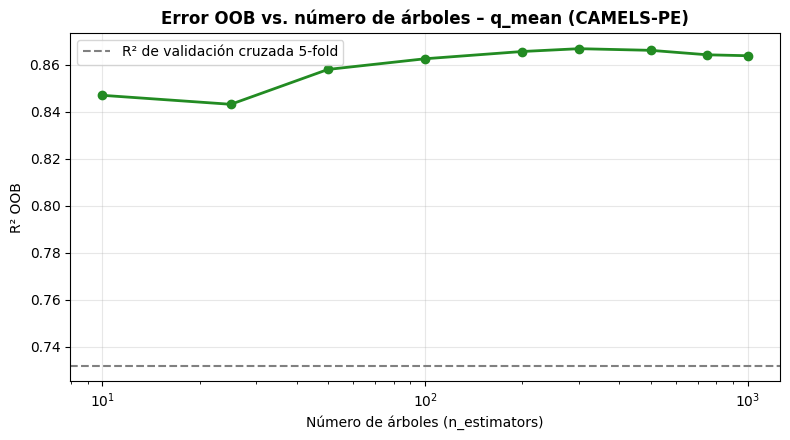

     10 árboles: R² OOB = 0.847
     25 árboles: R² OOB = 0.843
     50 árboles: R² OOB = 0.858
    100 árboles: R² OOB = 0.862
    200 árboles: R² OOB = 0.866
    300 árboles: R² OOB = 0.867
    500 árboles: R² OOB = 0.866
    750 árboles: R² OOB = 0.864
   1000 árboles: R² OOB = 0.864


In [ ]:
n_arboles = [10, 25, 50, 100, 200, 300, 500, 750, 1000]
oob_r2 = []
rf_oob = RandomForestRegressor(min_samples_leaf=2, oob_score=True, warm_start=True,
                               random_state=42, n_jobs=-1)
for n in n_arboles:
    rf_oob.set_params(n_estimators=n)   # warm_start=True: agrega árboles sin reentrenar los anteriores
    rf_oob.fit(X_cam, y_cam)
    oob_r2.append(rf_oob.oob_score_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_arboles, oob_r2, 'o-', lw=2, color='forestgreen')
ax.axhline(tabla_cam.loc['Random Forest (500)', 'R² CV'], color='gray', ls='--',
           label='R² de validación cruzada 5-fold')
ax.set_xscale('log')
ax.set_xlabel('Número de árboles (n_estimators)'); ax.set_ylabel('R² OOB')
ax.set_title('Error OOB vs. número de árboles – q_mean (CAMELS-PE)', fontweight='bold')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

for n, r in zip(n_arboles, oob_r2):
    print(f"  {n:>5} árboles: R² OOB = {r:.3f}")

El R² OOB se estabiliza a partir de ~200 árboles: agregar más no daña (Random Forest no sobreajusta por tener más árboles),
solo cuesta tiempo de cómputo.

¿Por qué el OOB (~0.87) sale más alto que el R² de validación cruzada de la tabla (~0.73)? La tabla **promedia el R² de 5 pliegues**
de solo ~27 cuencas cada uno: si un pliegue tiene poca variación de `q_mean`, su R² cae mucho y arrastra el promedio.
Si juntamos las predicciones de todos los pliegues y calculamos un único R² (siguiente celda), obtenemos un valor muy cercano al OOB.
Con pocos datos, **cómo** se calcula la métrica importa.

### 11.3 Predicho vs. observado

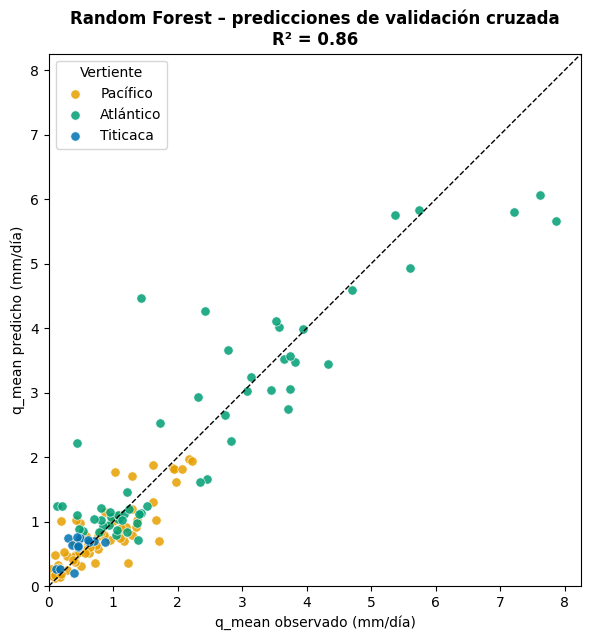

Error absoluto medio por vertiente (mm/día):
vertiente
Atlántico    0.546
Pacífico     0.224
Titicaca     0.189
Name: error_abs, dtype: float64


In [ ]:
rf_cam = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=-1)
y_pred_cv = cross_val_predict(rf_cam, X_cam, y_cam, cv=cv)   # cada cuenca predicha por un modelo que no la vio

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for reg, color in colores_vertiente.items():
    m = (camels['gauge_region'] == reg).values
    ax.scatter(y_cam[m], y_pred_cv[m], c=color, s=45, alpha=0.85, edgecolors='white',
               linewidths=0.5, label=nombres_vertiente[reg])
lim = [0, max(y_cam.max(), y_pred_cv.max()) * 1.05]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')
from sklearn.metrics import r2_score
ax.set_xlabel('q_mean observado (mm/día)'); ax.set_ylabel('q_mean predicho (mm/día)')
ax.set_title(f'Random Forest – predicciones de validación cruzada\nR² = {r2_score(y_cam, y_pred_cv):.2f}',
             fontweight='bold')
ax.legend(title='Vertiente')
plt.tight_layout()
plt.show()

err = pd.DataFrame({'obs': y_cam, 'pred': y_pred_cv, 'vertiente': camels['gauge_region'].map(nombres_vertiente)})
err['error_abs'] = (err['pred'] - err['obs']).abs()
print("Error absoluto medio por vertiente (mm/día):")
print(err.groupby('vertiente')['error_abs'].mean().round(3))

Fíjate en las cuencas amazónicas más húmedas (`q_mean` alto): el modelo tiende a **subestimarlas**.
Un Random Forest **no puede extrapolar**: su predicción es un promedio de valores vistos en entrenamiento, así que
nunca predice por encima del máximo (ni por debajo del mínimo) observado. Hay muy pocas cuencas tan húmedas para aprender de ellas.

### 11.4 Importancia de las variables: impureza vs. permutación

La importancia por **impureza** (MDI, `feature_importances_`) que vimos en la sección 9 tiene dos problemas conocidos:
- se calcula con los **datos de entrenamiento**, así que puede premiar variables que el modelo usa para memorizar;
- favorece variables **continuas con muchos valores distintos** y reparte la importancia entre variables **correlacionadas**.

La **importancia por permutación** es más confiable: en un conjunto de **prueba**, desordena aleatoriamente una columna
y mide cuánto empeora el R². Si el modelo depende de esa variable, el error sube mucho.

R² en prueba: 0.563


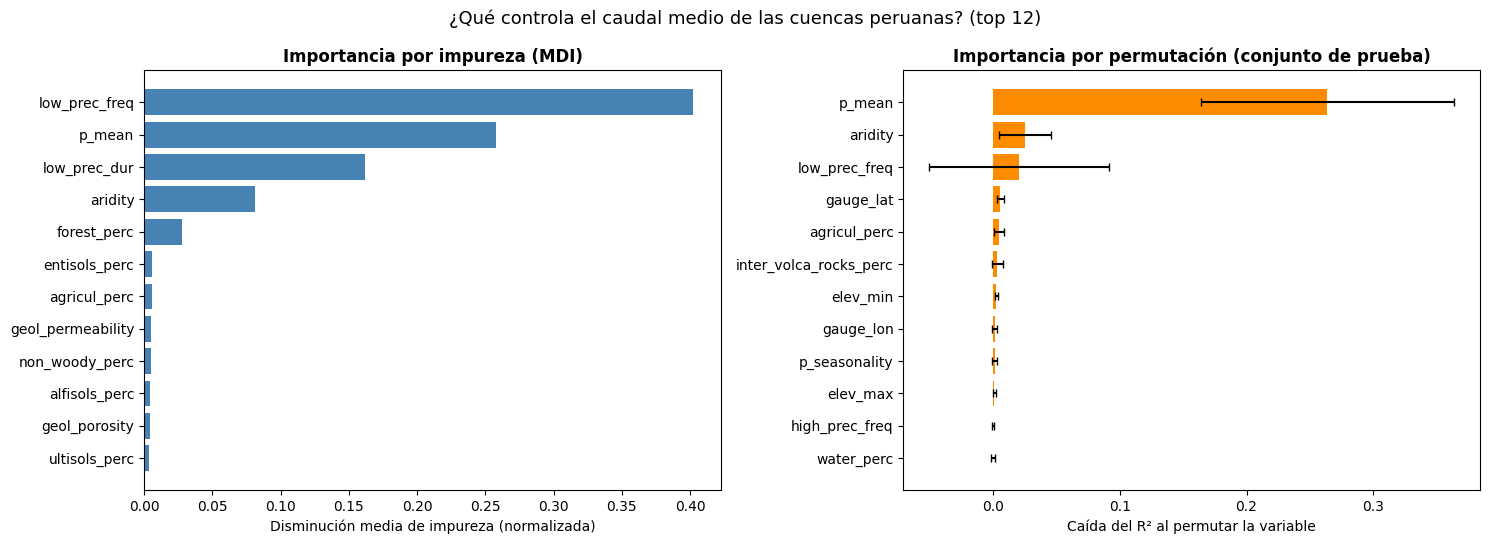

Top 5 por permutación:
p_mean           0.264
aridity          0.025
low_prec_freq    0.021
gauge_lat        0.006
agricul_perc     0.005


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_cam, y_cam, test_size=0.25, random_state=42)
rf_cam.fit(X_tr_c, y_tr_c)
print(f"R² en prueba: {rf_cam.score(X_te_c, y_te_c):.3f}")

imp_mdi = pd.Series(rf_cam.feature_importances_, index=cols_rf)
perm = permutation_importance(rf_cam, X_te_c, y_te_c, n_repeats=30, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=cols_rf)
imp_perm_sd = pd.Series(perm.importances_std, index=cols_rf)

top = 12
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
s = imp_mdi.sort_values().tail(top)
ejes[0].barh(s.index, s.values, color='steelblue')
ejes[0].set_xlabel('Disminución media de impureza (normalizada)')
ejes[0].set_title('Importancia por impureza (MDI)', fontweight='bold')

s = imp_perm.sort_values().tail(top)
ejes[1].barh(s.index, s.values, xerr=imp_perm_sd[s.index], color='darkorange', capsize=3)
ejes[1].set_xlabel('Caída del R² al permutar la variable')
ejes[1].set_title('Importancia por permutación (conjunto de prueba)', fontweight='bold')
plt.suptitle(f'¿Qué controla el caudal medio de las cuencas peruanas? (top {top})', fontsize=13)
plt.tight_layout()
plt.show()

print("Top 5 por permutación:")
print(imp_perm.sort_values(ascending=False).head(5).round(3).to_string())

**Interpretación:** los dos métodos **no coinciden**. La importancia por impureza pone primero a `low_prec_freq` (frecuencia de días secos)
y reparte mucho peso entre variables de precipitación correlacionadas; la importancia por permutación muestra que, en datos nuevos,
el modelo depende sobre todo de `p_mean` (precipitación media). Esto tiene sentido físico: el caudal medio es, ante todo,
la lluvia que cae en la cuenca menos lo que se evapora.

Fíjate también en las **barras de error** de la permutación: con solo 34 cuencas de prueba la incertidumbre es grande.

Ojo con las variables **correlacionadas** con `p_mean` (`aridity`, `forest_perc`, `ultisols_perc`, `low_prec_freq`…):
si el modelo puede usar cualquiera de ellas, al permutar una sola el resto la "reemplaza" y su importancia individual
puede verse pequeña aunque el grupo sea relevante. La importancia **no es causalidad**.

### 11.5 Dependencia parcial: ¿cómo responde el modelo a cada variable?

Un **gráfico de dependencia parcial** (PDP) muestra la predicción promedio del modelo cuando variamos una variable
y dejamos las demás como están en los datos. Permite ver *la forma* de la relación aprendida.

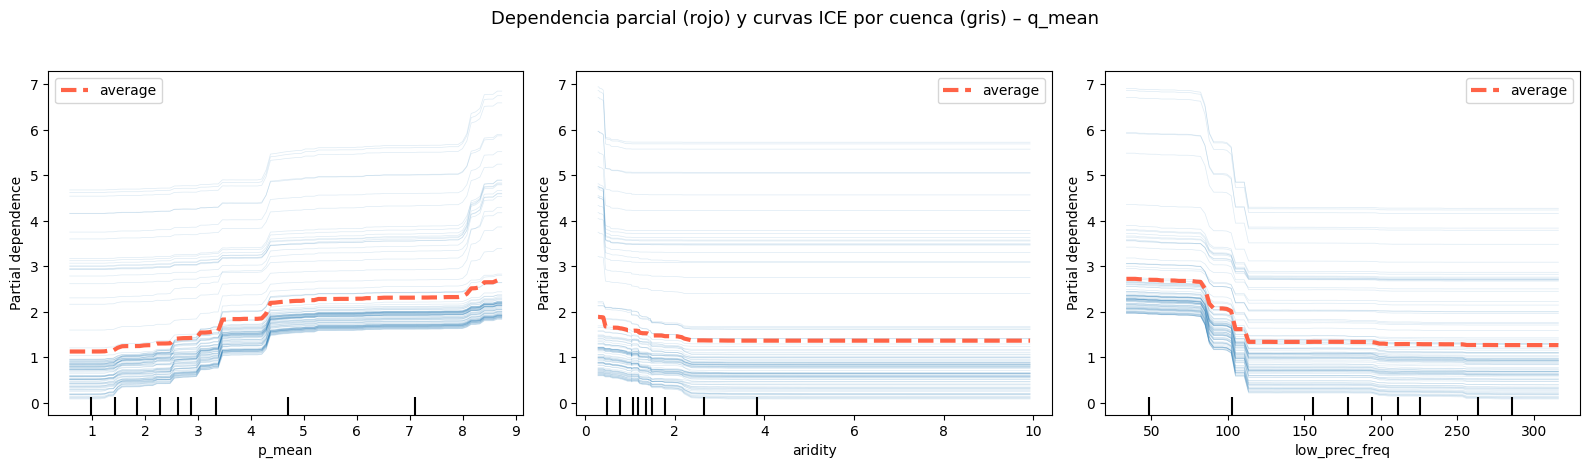

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

top3 = list(imp_perm.sort_values(ascending=False).index[:3])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
PartialDependenceDisplay.from_estimator(rf_cam, X_tr_c, top3, ax=ax, kind='both',
                                        subsample=100, random_state=42,
                                        ice_lines_kw={'alpha': 0.15}, pd_line_kw={'color': 'tomato', 'lw': 3})
plt.suptitle('Dependencia parcial (rojo) y curvas ICE por cuenca (gris) – q_mean', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

La relación con `p_mean` es creciente (más lluvia → más caudal), pero **en escalones**: un Random Forest es un promedio de funciones
constantes a trozos. Más allá del rango de entrenamiento la curva se vuelve **plana**: el Random Forest no extrapola.
`aridity` y `low_prec_freq` muestran el efecto inverso: cuencas más áridas o con más días secos producen menos caudal. Las curvas ICE (una por cuenca) muestran
si el efecto es parecido en todas las cuencas o si depende de otras variables (interacciones).

En el **Lab 8_4** profundizaremos en la interpretación con valores **SHAP**.

### 11.6 La trampa de las cuencas anidadas: validación cruzada por grupos

En CAMELS-PE, **119 de las 136 cuencas están anidadas**: una estación aguas arriba drena una parte de la cuenca de otra estación
aguas abajo (por ejemplo, decenas de estaciones del sistema Ucayali–Marañón comparten el mismo grupo `nested_group_id`).
Cuencas anidadas comparten territorio, clima y suelos, así que sus atributos **y** sus caudales son muy parecidos.

Con un `KFold` aleatorio, es muy probable que una cuenca esté en prueba y su "hermana" aguas arriba en entrenamiento.
El modelo acierta porque ya vio casi la misma cuenca: el error de validación sale **optimista**.

La solución es **`GroupKFold`**: todas las cuencas de un mismo grupo anidado van juntas al mismo pliegue.
Así simulamos el caso real: predecir una cuenca de un sistema fluvial del que no tenemos ninguna estación.

39 grupos de cuencas anidadas; el más grande tiene 54 estaciones


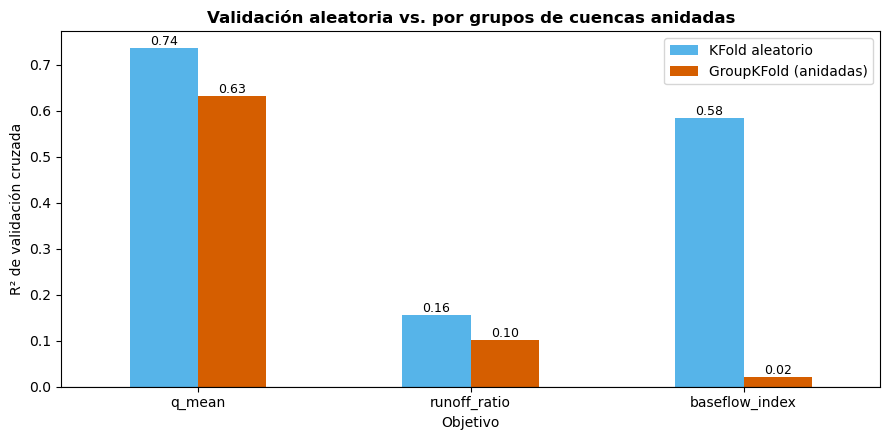

,KFold aleatorio,GroupKFold (anidadas)
Objetivo,,
q_mean,0.736,0.632
runoff_ratio,0.156,0.100
baseflow_index,0.585,0.020


In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score

grupos = camels['nested_group_id']
print(f"{grupos.nunique()} grupos de cuencas anidadas; el más grande tiene {grupos.value_counts().iloc[0]} estaciones")

cv_grupos = GroupKFold(n_splits=5)
rf_cmp = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)

filas = []
for obj in ['q_mean', 'runoff_ratio', 'baseflow_index']:
    r_aleat = cross_val_score(rf_cmp, X_cam, camels[obj], cv=cv, scoring='r2')
    r_grupo = cross_val_score(rf_cmp, X_cam, camels[obj], cv=cv_grupos, groups=grupos, scoring='r2')
    filas.append({'Objetivo': obj, 'KFold aleatorio': r_aleat.mean(), 'GroupKFold (anidadas)': r_grupo.mean()})
tabla_cv = pd.DataFrame(filas).set_index('Objetivo')

ax = tabla_cv.plot.bar(figsize=(9, 4.5), color=['#56B4E9', '#D55E00'], rot=0)
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('R² de validación cruzada')
ax.set_title('Validación aleatoria vs. por grupos de cuencas anidadas', fontweight='bold')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f', fontsize=9)
plt.tight_layout()
plt.show()
tabla_cv.round(3)

**Resultado clave:** para `q_mean` la caída es moderada (el balance hídrico se transfiere bien entre sistemas fluviales), pero para
`baseflow_index` el R² **se desploma** al validar por grupos. El "buen" resultado del `KFold` aleatorio venía de cuencas hermanas
anidadas, no de que el modelo entendiera qué controla el flujo base.

> **Regla práctica para datos ambientales:** cuando las observaciones están relacionadas en el espacio o el tiempo
> (cuencas anidadas, estaciones vecinas, días consecutivos), la validación cruzada aleatoria **sobreestima** el desempeño.
> Usa validación por **grupos**, **bloques espaciales** o **bloques temporales** según el problema.

---
## 🔬 Ejercicio: regionalización del índice de flujo base

El **índice de flujo base** (`baseflow_index`, BFI) es la fracción del caudal que proviene de agua subterránea y
almacenamientos lentos. Es clave para estimar la disponibilidad de agua en estiaje.

1. Entrena un `RandomForestRegressor` para predecir `baseflow_index` con los mismos predictores `cols_rf`.
   Evalúalo con `GroupKFold` por `nested_group_id` y compáralo con una regresión lineal evaluada de la misma forma.
2. Calcula la importancia por permutación. ¿Qué grupo de variables (clima, suelo, geología…) domina? ¿Coincide con lo que esperarías físicamente?
3. Prueba a limitar la complejidad (`max_depth`, `min_samples_leaf`, `max_features`). ¿Mejora el R² por grupos?
4. **Discusión:** ¿por qué el BFI es mucho más difícil de regionalizar que `q_mean`? ¿Qué información faltaría en los atributos?

In [ ]:
# --- Solución ---
y_bfi = camels['baseflow_index']

# 1. RF vs. regresión lineal con validación por grupos
rf_bfi = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=-1)
lr_bfi = make_pipeline(StandardScaler(), LinearRegression())
for nombre, m in [('Random Forest', rf_bfi), ('Regresión lineal', lr_bfi)]:
    r = cross_val_score(m, X_cam, y_bfi, cv=cv_grupos, groups=grupos, scoring='r2')
    print(f"{nombre:<18} R² GroupKFold = {r.mean():.3f} ± {r.std():.3f}")

# 2. Importancia por permutación (agrupada por tipo de variable)
Xtr, Xte, ytr, yte = train_test_split(X_cam, y_bfi, test_size=0.25, random_state=42)
rf_bfi.fit(Xtr, ytr)
p = permutation_importance(rf_bfi, Xte, yte, n_repeats=30, random_state=42, n_jobs=-1)
imp_bfi = pd.Series(p.importances_mean, index=cols_rf).sort_values(ascending=False)
grupo_de = {v: g for g, vs in predictores.items() for v in vs}
print("\nTop 8 variables:")
print(imp_bfi.head(8).round(3).to_string())
print("\nImportancia total por grupo:")
print(imp_bfi.groupby(imp_bfi.index.map(grupo_de)).sum().sort_values(ascending=False).round(3).to_string())

# 3. Limitar la complejidad
print()
for params in [dict(max_depth=3), dict(min_samples_leaf=8), dict(max_features=0.33, min_samples_leaf=4)]:
    m = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1, **params)
    r = cross_val_score(m, X_cam, y_bfi, cv=cv_grupos, groups=grupos, scoring='r2')
    print(f"{str(params):<45} R² GroupKFold = {r.mean():.3f}")

Random Forest      R² GroupKFold = 0.032 ± 0.599
Regresión lineal   R² GroupKFold = -9.264 ± 18.769



Top 8 variables:
elev_max            0.172
agricul_perc        0.080
alfisols_perc       0.041
ultisols_perc       0.034
non_veget_perc      0.023
gauge_lat           0.019
high_prec_freq      0.019
inceptisols_perc    0.014

Importancia total por grupo:
Topografía    0.187
Cobertura     0.109
Suelo         0.099
Ubicación     0.029
Humano        0.027
Clima         0.027
Geología      0.012



{'max_depth': 3}                              R² GroupKFold = 0.006


{'min_samples_leaf': 8}                       R² GroupKFold = -0.091


{'max_features': 0.33, 'min_samples_leaf': 4} R² GroupKFold = 0.087


---
## 12. Resumen

| Concepto | Idea clave |
|---|---|
| Árbol de decisión | Divide recursivamente las características para crear un diagrama de flujo de preguntas de sí/no |
| Árbol de clasificación | Predice la clase mayoritaria en cada hoja; las divisiones minimizan la impureza de Gini |
| Árbol de regresión | Predice el valor objetivo medio en cada hoja; las divisiones minimizan la varianza |
| Impureza de Gini | Mide la mezcla de clases; 0 = pura, 0.5 = mezcla máxima (binaria) |
| Ganancia de información | Disminución de la impureza a partir de una división; el árbol elige la división con la mayor ganancia |
| Sobreajuste | Los árboles ilimitados memorizan el ruido; se controla con `max_depth`, `min_samples_leaf` |
| Bosque aleatorio | Conjunto de árboles entrenados con muestras bootstrap y subconjuntos aleatorios de características |
| Bagging | Bootstrap + agregación reduce la varianza sin aumentar el sesgo, si los árboles están poco correlacionados |
| No se necesita escalado | Los árboles se dividen según umbrales dentro de características individuales, no según distancias |
| Error OOB | Validación "gratis" con las muestras que cada árbol no vio |
| Importancia MDI vs. permutación | MDI es rápida pero sesgada; la permutación en datos de prueba es más confiable. Ninguna es causalidad |
| No extrapola | Un RF nunca predice fuera del rango de valores vistos en entrenamiento |
| Validación por grupos | Con datos espacialmente relacionados (cuencas anidadas) la CV aleatoria es optimista: usar `GroupKFold` |
| Radiación de onda corta | El RF captura la física atmosférica no lineal; SZA, CLD_FRAC y AOD son los principales predictores |
| CAMELS-PE | `p_mean` controla `q_mean`; el flujo base es mucho más difícil de regionalizar |

### Hiperparámetros clave

| Parámetro | Árbol de decisión | Bosque aleatorio |
|---|---|---|
| `max_depth` | Limita la profundidad del árbol (fundamental para evitar el sobreajuste) | Menos crítico (el conjunto promedia el sobreajuste), pero sigue siendo útil |
| `n_estimators` | n/a | Número de árboles (típico: 100–500; rendimientos decrecientes a partir de ~200) |
| `max_features` | n/a | Características consideradas por división. Por defecto `'sqrt'` en clasificación y `1.0` (todas) en regresión; valores como `0.33` reducen la correlación entre árboles |
| `min_samples_leaf` | Muestras mínimas en una hoja (evita hojas pequeñas y ruidosas) | Igual |
| `oob_score` | n/a | `True` para calcular el R²/exactitud *out-of-bag* |